In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Parse the policy into segments


1. Detect headings
2. Group paragraphs under each heading
3. Check section length
4. If section <= max length:
      keep as one segment
   else:
      split within section by paragraphs/sentences
5. If no headings:
      split by paragraphs
6. Merge very short adjacent paragraphs
7. Split very long paragraphs

In [ ]:
"""Privacy-policy segmentation. Importing this module does not load a model.

Before use, assign the saved Stage 1 tokenizer to segment_tokenizer.
MAX_TOKENS limits evidence text; model_max_tokens optionally limits the complete
formatted model input, including special tokens.
"""

'Privacy-policy segmentation. Importing this module does not load a model.\n\nBefore use, assign the saved Stage 1 tokenizer to segment_tokenizer.\nMAX_TOKENS limits evidence text; model_max_tokens optionally limits the complete\nformatted model input, including special tokens.\n'

In [ ]:
import re
from typing import List, Dict, Optional

from transformers import AutoTokenizer

In [ ]:
# ============================================================
# Configuration
# ============================================================

SEGMENT_TOKENIZER_NAME = "microsoft/deberta-v3-base"

# Load the exact tokenizer used by the Stage 1 model
segment_tokenizer = AutoTokenizer.from_pretrained(
    SEGMENT_TOKENIZER_NAME,
    trust_remote_code=True
)

# Recommended starting values.
# These are segmentation limits, NOT the model's maximum context length.
# MIN_TOKENS = 40
TARGET_TOKENS = 60
MAX_TOKENS = 100

In [ ]:
# ============================================================
# Token utilities
# ============================================================

def count_tokens(text: str) -> int:

    return len(
        segment_tokenizer.encode(
            text,
            add_special_tokens=False
        )
    )

In [ ]:
# ============================================================
# Basic text processing
# ============================================================

def clean_text(text: str) -> str:

    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")

    # Remove unnecessary spaces
    text = re.sub(
        r"[ \t]+",
        " ",
        text
    )

    return text.strip()


def split_paragraphs(text: str) -> List[str]:
    """
    True paragraphs are separated by blank lines.
    """

    text = clean_text(text)

    paragraphs = re.split(
        r"\n\s*\n+",
        text
    )

    paragraphs = [
        re.sub(
            r"\s+",
            " ",
            paragraph
        ).strip()
        for paragraph in paragraphs
        if paragraph.strip()
    ]

    return paragraphs


def split_sentences(text: str) -> List[str]:

    # Convert single line breaks into spaces first.
    # This fixes wrapped privacy-policy text.
    text = re.sub(
        r"\s*\n\s*",
        " ",
        text
    )

    sentences = re.split(
        r'(?<=[.!?])\s+(?=[A-Z0-9“"])',
        text
    )

    return [
        s.strip()
        for s in sentences
        if s.strip()
    ]


In [ ]:
# ============================================================
# Heading detection
# ============================================================

def is_heading(text: str) -> bool:

    text = text.strip()

    if not text:
        return False

    words = text.split()

    if len(words) > 15:
        return False

    # Normal sentence → probably not heading
    if text.endswith((".", "?", "!")):
        return False

    # Numbered heading
    if re.match(
        r"^\d+(?:\.\d+)*[\.\)]?\s+\S+",
        text
    ):
        return True

    # Colon heading
    if text.endswith(":"):
        return True

    # ALL CAPS
    letters = [
        c for c in text
        if c.isalpha()
    ]

    if letters:

        uppercase_ratio = (
            sum(c.isupper() for c in letters)
            / len(letters)
        )

        if uppercase_ratio >= 0.8:
            return True

    # Title Case
    title_words = sum(
        1
        for word in words
        if word[:1].isupper()
    )

    if (
        len(words) <= 12
        and title_words / len(words) >= 0.7
    ):
        return True

    return False

In [ ]:
# ============================================================
# Long-text splitting
# ============================================================

def hard_token_split(
    text: str,
    max_tokens: int = MAX_TOKENS
) -> List[str]:
    """
    Last-resort token-level split.

    This is only used when one single sentence itself is longer
    than max_tokens.
    """

    token_ids = segment_tokenizer.encode(
        text,
        add_special_tokens=False
    )

    chunks = []

    for start in range(
        0,
        len(token_ids),
        max_tokens
    ):

        chunk_ids = token_ids[
            start:start + max_tokens
        ]

        chunk_text = segment_tokenizer.decode(
            chunk_ids,
            skip_special_tokens=True
        ).strip()

        if chunk_text:
            chunks.append(chunk_text)

    return chunks

In [ ]:
# ============================================================
# Paragraph accumulation
# ============================================================

def pack_sentences(
    text: str,
    target_tokens: int = TARGET_TOKENS,
    max_tokens: int = MAX_TOKENS,
    max_sentences: int = 2
):

    sentences = split_sentences(text)

    if not sentences:
        return []

    chunks = []
    current = []

    for sentence in sentences:

        # --------------------------------
        # Extremely long single sentence
        # --------------------------------

        if count_tokens(sentence) > max_tokens:

            if current:
                chunks.append(
                    " ".join(current)
                )
                current = []

            chunks.extend(
                hard_token_split(
                    sentence,
                    max_tokens=max_tokens
                )
            )

            continue

        # --------------------------------
        # First sentence
        # --------------------------------

        if not current:

            current = [sentence]
            continue

        current_text = " ".join(current)

        candidate = (
            current_text
            + " "
            + sentence
        )

        # --------------------------------
        # Stop if token limit exceeded
        # --------------------------------

        if count_tokens(candidate) > max_tokens:

            chunks.append(
                current_text
            )

            current = [sentence]

            continue

        # --------------------------------
        # Stop if enough sentences
        # --------------------------------

        if len(current) >= max_sentences:

            chunks.append(
                current_text
            )

            current = [sentence]

            continue

        # --------------------------------
        # Stop if target size reached
        # --------------------------------

        if count_tokens(current_text) >= target_tokens:

            chunks.append(
                current_text
            )

            current = [sentence]

            continue

        current.append(sentence)

    if current:

        chunks.append(
            " ".join(current)
        )

    return chunks

In [ ]:
# ============================================================
# Section processing
# ============================================================

def create_section_segments(
    heading: Optional[str],
    text: str
) -> List[Dict]:

    chunks = pack_sentences(text)

    return [
        {
            "heading": heading,
            "text": chunk
        }
        for chunk in chunks
    ]


In [ ]:
# ============================================================
# Main segmentation function
# ============================================================

"""
    Segment a complete privacy policy.

    Rules
    -----
    1. Split policy into paragraphs.
    2. Detect section headings.
    3. If headings exist:
         group paragraphs under their heading.
    4. Pack paragraphs within each section.
    5. Split sections that are too long.
    6. If no headings exist:
         perform paragraph-aware token chunking.
    7. Preserve heading metadata.
"""

def segment_policy(
    policy_text: str
) -> List[Dict]:

    paragraphs = split_paragraphs(
        policy_text
    )

    if not paragraphs:
        return []


    # ========================================================
    # Detect headings
    # ========================================================

    heading_flags = [
        is_heading(p)
        for p in paragraphs
    ]


    has_headings = any(
        heading_flags
    )

    segments = []


    # ========================================================
    # CASE 1 — headings exist
    # ========================================================

    if has_headings:

        current_heading = None
        current_content = []

        for paragraph in paragraphs:

            if is_heading(paragraph):

                if current_content:

                    section_text = " ".join(
                        current_content
                    )

                    segments.extend(
                        create_section_segments(
                            current_heading,
                            section_text
                        )
                    )

                current_heading = paragraph
                current_content = []

            else:

                current_content.append(
                    paragraph
                )


        if current_content:

            section_text = " ".join(
                current_content
            )

            segments.extend(
                create_section_segments(
                    current_heading,
                    section_text
                )
            )


    # ========================================================
    # CASE 2 — no headings
    # ========================================================

    else:

        # If real paragraphs exist, process each paragraph
        # independently unless extremely short.

        if len(paragraphs) > 1:

            for paragraph in paragraphs:

                segments.extend(
                    create_section_segments(
                        None,
                        paragraph
                    )
                )

        # Important fallback:
        # whole policy arrived as ONE paragraph
        else:

            segments.extend(
                create_section_segments(
                    None,
                    paragraphs[0]
                )
            )


    # ========================================================
    # Final output
    # ========================================================

    final_segments = []

    for i, segment in enumerate(
        segments
    ):

        text = segment["text"]
        heading = segment["heading"]

        if heading:

            model_input = (
                f"Section: {heading}\n\n"
                f"Text: {text}"
            )

        else:

            model_input = text


        final_segments.append({
            "segment_id": i,
            "heading": heading,
            "text": text,

            "text_token_count":
                count_tokens(text),

            "model_input_token_count":
                count_tokens(model_input),

            "model_input":
                model_input
        })


    return final_segments


# ============================================================
# Example
# ============================================================

if __name__ == "__main__":

    example_policy = """
Information We Collect

We collect your name, email address and phone number when you create an account.

We may also automatically collect your IP address, device identifiers and information about how you use our services.

How We Use Your Information

We use your personal information to provide our services, improve our products and communicate with you.

We may also use aggregated information for analytics and research.

Sharing Your Information

We may share your information with service providers that help us operate our platform.

We may also disclose information where required by law.

Data Retention

We retain account information for as long as your account remains active.

Some transaction records may be retained for seven years where required by law.

Your Privacy Rights

You may request access to or correction of your personal information.

You may also request deletion of your account by contacting our support team.
"""

    results = segment_policy(
        example_policy
    )

    for segment in results:

        print("=" * 80)
        print(
            f"Segment ID: "
            f"{segment['segment_id']}"
        )
        print(
            f"Heading: "
            f"{segment['heading']}"
        )
        print(
            f"Text tokens: "
            f"{segment['text_token_count']}"
        )
        print(
            f"Model input tokens: "
            f"{segment['model_input_token_count']}"
        )

        print("\nMODEL INPUT:\n")
        print(
            segment["model_input"]
        )

Segment ID: 0
Heading: Information We Collect
Text tokens: 36
Model input tokens: 43

MODEL INPUT:

Section: Information We Collect

Text: We collect your name, email address and phone number when you create an account. We may also automatically collect your IP address, device identifiers and information about how you use our services.
Segment ID: 1
Heading: How We Use Your Information
Text tokens: 29
Model input tokens: 38

MODEL INPUT:

Section: How We Use Your Information

Text: We use your personal information to provide our services, improve our products and communicate with you. We may also use aggregated information for analytics and research.
Segment ID: 2
Heading: Sharing Your Information
Text tokens: 25
Model input tokens: 32

MODEL INPUT:

Section: Sharing Your Information

Text: We may share your information with service providers that help us operate our platform. We may also disclose information where required by law.
Segment ID: 3
Heading: Data Retention
Text tokens: 27


#### Test


In [ ]:
policy = """
Information We Collect

We collect your name, email address and phone number when you create an account.

We may also collect your IP address and device identifiers automatically when you use our services.

How We Use Your Information

We use your personal information to provide our services, improve our products and communicate with you.

Sharing Your Information

We may share your information with service providers that help us operate our platform.

Your Rights

You may request access to, correction of, or deletion of your personal information.
"""

segments = segment_policy(policy)

for segment in segments:
    print("=" * 80)
    print("ID:", segment["segment_id"])
    print("Heading:", segment["heading"])
    print("Tokens:", segment["text_token_count"])
    print(segment["text"])

ID: 0
Heading: Information We Collect
Tokens: 33
We collect your name, email address and phone number when you create an account. We may also collect your IP address and device identifiers automatically when you use our services.
ID: 1
Heading: How We Use Your Information
Tokens: 18
We use your personal information to provide our services, improve our products and communicate with you.
ID: 2
Heading: Sharing Your Information
Tokens: 15
We may share your information with service providers that help us operate our platform.
ID: 3
Heading: Your Rights
Tokens: 16
You may request access to, correction of, or deletion of your personal information.


## Data Check


#### split English policies from the dataset


In [ ]:
import json
from pathlib import Path

In [ ]:
input_path = Path(
    "/content/drive/MyDrive/TP13_Project/privacy_policies_5categories.jsonl"
)

output_path = Path(
    "/content/drive/MyDrive/TP13_Project/privacy_policies_english.jsonl"
)

In [ ]:
# ============================================================
# Filter English policies
# ============================================================

total_count = 0
english_count = 0
other_count = 0

with open(input_path, "r", encoding="utf-8") as infile, \
     open(output_path, "w", encoding="utf-8") as outfile:

    for line in infile:

        line = line.strip()

        if not line:
            continue

        policy = json.loads(line)

        total_count += 1

        language = policy.get("language")

        # Different labels
        if language in ["English", "english", "EN", "en"]:

            outfile.write(
                json.dumps(
                    policy,
                    ensure_ascii=False
                )
                + "\n"
            )

            english_count += 1

        else:
            other_count += 1

In [ ]:
# ============================================================
# Print results
# ============================================================

print("Filtering completed.")
print(f"Total policies:   {total_count}")
print(f"English policies: {english_count}")
print(f"Other policies:   {other_count}")
print(f"Saved to: {output_path}")

Filtering completed.
Total policies:   620
English policies: 529
Other policies:   91
Saved to: /content/drive/MyDrive/TP13_Project/privacy_policies_english.jsonl


#### Audit dataset

In [ ]:
import json
from pathlib import Path
from collections import Counter, defaultdict

In [ ]:
# ============================================================
# 1. File path
# ============================================================

input_path = Path(
    "/content/drive/MyDrive/TP13_Project/privacy_policies_english.jsonl"
)


# ============================================================
# 2. Counters
# ============================================================

dataset_counter = Counter()
source_split_counter = Counter()
synthetic_counter = Counter()

dataset_split_counter = defaultdict(Counter)
dataset_synthetic_counter = defaultdict(Counter)

duplicate_policy_count = 0
duplicate_group_count = 0

policies = []

In [ ]:
# ============================================================
# 3. Read policies
# ============================================================

with open(input_path, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        policy = json.loads(line)
        policies.append(policy)

        dataset = policy.get("dataset")
        source_split = policy.get("source_split")
        contains_synthetic = policy.get("contains_synthetic")

        # --------------------------------
        # Dataset distribution
        # --------------------------------

        dataset_counter[dataset] += 1

        # --------------------------------
        # Source split distribution
        # --------------------------------

        source_split_counter[source_split] += 1
        dataset_split_counter[dataset][source_split] += 1

        # --------------------------------
        # Synthetic distribution
        # --------------------------------

        synthetic_counter[contains_synthetic] += 1
        dataset_synthetic_counter[dataset][contains_synthetic] += 1

        # --------------------------------
        # Exact duplicate information
        # --------------------------------

        duplicate_ids = policy.get(
            "exact_duplicate_record_ids"
        )

        if duplicate_ids:
            duplicate_policy_count += 1



In [ ]:
# ============================================================
# 4. Build duplicate groups by text_sha256
# ============================================================

sha_groups = defaultdict(list)

for policy in policies:

    sha = policy.get("text_sha256")

    if sha:
        sha_groups[sha].append(
            policy.get("record_id")
        )


duplicate_groups = {
    sha: ids
    for sha, ids in sha_groups.items()
    if len(ids) > 1
}

duplicate_group_count = len(duplicate_groups)

In [ ]:
# ============================================================
# 5. Print dataset distribution
# ============================================================

print("=" * 70)
print("DATASET DISTRIBUTION")
print("=" * 70)

for dataset, count in dataset_counter.items():
    print(f"{dataset}: {count}")

DATASET DISTRIBUTION
APP-350: 350
MAPP: 64
OPP-115: 115


In [ ]:
# ============================================================
# 6. Print source_split distribution
# ============================================================

print("\n" + "=" * 70)
print("SOURCE SPLIT DISTRIBUTION")
print("=" * 70)

for split, count in source_split_counter.items():
    print(f"{split}: {count}")


print("\nPer dataset:")

for dataset, counter in dataset_split_counter.items():

    print(f"\n{dataset}")

    for split, count in counter.items():
        print(f"  {split}: {count}")


SOURCE SPLIT DISTRIBUTION
TEST: 112
TRAINING: 188
VALIDATION: 62
TRAIN: 52
None: 115

Per dataset:

APP-350
  TEST: 100
  TRAINING: 188
  VALIDATION: 62

MAPP
  TRAIN: 52
  TEST: 12

OPP-115
  None: 115


In [ ]:
# ============================================================
# 7. Print synthetic distribution
# ============================================================

print("\n" + "=" * 70)
print("SYNTHETIC FLAG DISTRIBUTION")
print("=" * 70)

for value, count in synthetic_counter.items():
    print(f"{value}: {count}")


print("\nPer dataset:")

for dataset, counter in dataset_synthetic_counter.items():

    print(f"\n{dataset}")

    for value, count in counter.items():
        print(f"  {value}: {count}")


SYNTHETIC FLAG DISTRIBUTION
False: 208
True: 142
None: 179

Per dataset:

APP-350
  False: 208
  True: 142

MAPP
  None: 64

OPP-115
  None: 115


In [ ]:
# ============================================================
# 8. Print exact duplicate information
# ============================================================

print("\n" + "=" * 70)
print("EXACT DUPLICATE INFORMATION")
print("=" * 70)

print(
    f"Policies with exact_duplicate_record_ids: "
    f"{duplicate_policy_count}"
)

print(
    f"Duplicate SHA-256 groups: "
    f"{duplicate_group_count}"
)


# Show several duplicate groups
if duplicate_groups:

    print("\nExample duplicate groups:")

    for i, (sha, ids) in enumerate(
        duplicate_groups.items()
    ):

        print(f"\nGroup {i + 1}")
        print(f"SHA: {sha}")
        print("Records:")

        for record_id in ids:
            print(f"  - {record_id}")

        if i >= 4:
            break


EXACT DUPLICATE INFORMATION
Policies with exact_duplicate_record_ids: 2
Duplicate SHA-256 groups: 0


In [ ]:
# ============================================================
# 9. Summary
# ============================================================

print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)

print(f"Total English policies: {len(policies)}")
print(f"Datasets: {dict(dataset_counter)}")
print(f"Source splits: {dict(source_split_counter)}")
print(f"Synthetic flags: {dict(synthetic_counter)}")
print(f"Duplicate groups: {duplicate_group_count}")


SUMMARY
Total English policies: 529
Datasets: {'APP-350': 350, 'MAPP': 64, 'OPP-115': 115}
Source splits: {'TEST': 112, 'TRAINING': 188, 'VALIDATION': 62, 'TRAIN': 52, None: 115}
Synthetic flags: {False: 208, True: 142, None: 179}
Duplicate groups: 0


#### synthetic check

In [ ]:
# ============================================================
# Cross-tab:
# dataset × source_split × synthetic flag
# ============================================================

stats = defaultdict(
    lambda: defaultdict(Counter)
)


with open(input_path, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        policy = json.loads(line)

        dataset = policy.get("dataset")
        source_split = policy.get("source_split")
        synthetic = policy.get("contains_synthetic")

        stats[dataset][source_split][synthetic] += 1


# ============================================================
# Print results
# ============================================================

print("=" * 70)
print("DATASET × SOURCE_SPLIT × SYNTHETIC")
print("=" * 70)


for dataset, split_data in stats.items():

    print(f"\n{dataset}")
    print("-" * 50)

    for split, synthetic_counts in split_data.items():

        print(f"  Split: {split}")

        for synthetic, count in synthetic_counts.items():

            print(
                f"      contains_synthetic={synthetic}: "
                f"{count}"
            )

DATASET × SOURCE_SPLIT × SYNTHETIC

APP-350
--------------------------------------------------
  Split: TEST
      contains_synthetic=False: 100
  Split: TRAINING
      contains_synthetic=True: 106
      contains_synthetic=False: 82
  Split: VALIDATION
      contains_synthetic=False: 26
      contains_synthetic=True: 36

MAPP
--------------------------------------------------
  Split: TRAIN
      contains_synthetic=None: 52
  Split: TEST
      contains_synthetic=None: 12

OPP-115
--------------------------------------------------
  Split: None
      contains_synthetic=None: 115


#### Training/validation/testing split

In [ ]:
import random

In [ ]:
# ============================================================
# 1. Configuration
# ============================================================

RANDOM_SEED = 42

random.seed(RANDOM_SEED)

input_path = Path(
    "/content/drive/MyDrive/TP13_Project/privacy_policies_english.jsonl"
)

output_dir = Path(
    "/content/drive/MyDrive/TP13_Project/splits"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

train_path = output_dir / "train_policies.jsonl"
validation_path = output_dir / "validation_policies.jsonl"
test_path = output_dir / "test_policies.jsonl"


In [ ]:
# ============================================================
# 2. Load policies
# ============================================================

policies = []

with open(input_path, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        policies.append(
            json.loads(line)
        )


print(
    f"Loaded {len(policies)} English policies."
)

Loaded 529 English policies.


In [ ]:
# ============================================================
# 3. Separate datasets
# ============================================================

app350 = [
    p for p in policies
    if p.get("dataset") == "APP-350"
]

mapp = [
    p for p in policies
    if p.get("dataset") == "MAPP"
]

opp115 = [
    p for p in policies
    if p.get("dataset") == "OPP-115"
]


print(f"APP-350: {len(app350)}")
print(f"MAPP:    {len(mapp)}")
print(f"OPP-115: {len(opp115)}")

APP-350: 350
MAPP:    64
OPP-115: 115


In [ ]:
# ============================================================
# 4. APP-350
#
# Preserve official split.
#
# TRAINING:
#   keep both real + source-synthetic
#
# VALIDATION:
#   keep real policies only
#
# TEST:
#   official test is already real-only
# ============================================================

app_train = [
    p for p in app350
    if p.get("source_split") == "TRAINING"
]

app_validation = [
    p for p in app350
    if (
        p.get("source_split") == "VALIDATION"
        and p.get("contains_synthetic") is False
    )
]

app_test = [
    p for p in app350
    if (
        p.get("source_split") == "TEST"
        and p.get("contains_synthetic") is False
    )
]


# Keep track of excluded synthetic validation policies.
app_validation_synthetic_excluded = [
    p for p in app350
    if (
        p.get("source_split") == "VALIDATION"
        and p.get("contains_synthetic") is True
    )
]

In [ ]:
# ============================================================
# 5. MAPP
#
# Preserve official split.
# ============================================================

mapp_train = [
    p for p in mapp
    if p.get("source_split") == "TRAIN"
]

mapp_test = [
    p for p in mapp
    if p.get("source_split") == "TEST"
]


In [ ]:
# ============================================================
# 6. OPP-115
#
# No official split.
# Create policy-level:
#
# 70% train
# 15% validation
# 15% test
# ============================================================

opp115_shuffled = opp115.copy()

random.shuffle(
    opp115_shuffled
)

n_opp = len(
    opp115_shuffled
)

n_train = int(
    n_opp * 0.70
)

n_validation = int(
    n_opp * 0.15
)


opp_train = (
    opp115_shuffled[:n_train]
)

opp_validation = (
    opp115_shuffled[
        n_train:
        n_train + n_validation
    ]
)

opp_test = (
    opp115_shuffled[
        n_train + n_validation:
    ]
)

In [ ]:
# ============================================================
# 7. Combine final splits
# ============================================================

train_policies = (
    app_train
    + mapp_train
    + opp_train
)

validation_policies = (
    app_validation
    + opp_validation
)

test_policies = (
    app_test
    + mapp_test
    + opp_test
)


# Shuffle within each final split.
random.shuffle(train_policies)
random.shuffle(validation_policies)
random.shuffle(test_policies)

In [ ]:
# ============================================================
# 8. Safety check:
# No policy may occur in more than one split
# ============================================================

train_ids = {
    p["record_id"]
    for p in train_policies
}

validation_ids = {
    p["record_id"]
    for p in validation_policies
}

test_ids = {
    p["record_id"]
    for p in test_policies
}


assert train_ids.isdisjoint(
    validation_ids
), "Train/Validation leakage detected!"

assert train_ids.isdisjoint(
    test_ids
), "Train/Test leakage detected!"

assert validation_ids.isdisjoint(
    test_ids
), "Validation/Test leakage detected!"

In [ ]:
# ============================================================
# 9. Extra safety:
# Test must not contain APP-350 synthetic policies
# ============================================================

for policy in test_policies:

    if policy.get("dataset") == "APP-350":

        assert (
            policy.get("contains_synthetic")
            is False
        ), "Synthetic APP-350 policy found in test!"

In [ ]:
# ============================================================
# 10. Save JSONL
# ============================================================

def save_jsonl(data, path):

    with open(
        path,
        "w",
        encoding="utf-8"
    ) as f:

        for record in data:

            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                )
                + "\n"
            )


save_jsonl(
    train_policies,
    train_path
)

save_jsonl(
    validation_policies,
    validation_path
)

save_jsonl(
    test_policies,
    test_path
)

In [ ]:
# ============================================================
# 11. Print results
# ============================================================

print("\n" + "=" * 70)
print("FINAL SPLIT")
print("=" * 70)

print(
    f"Train:      "
    f"{len(train_policies)}"
)

print(
    f"Validation: "
    f"{len(validation_policies)}"
)

print(
    f"Test:       "
    f"{len(test_policies)}"
)

print(
    f"Total used: "
    f"{len(train_policies) + len(validation_policies) + len(test_policies)}"
)

print(
    f"Excluded APP-350 synthetic validation policies: "
    f"{len(app_validation_synthetic_excluded)}"
)


print("\nBreakdown:")

print(
    f"Train -> "
    f"APP-350={len(app_train)}, "
    f"MAPP={len(mapp_train)}, "
    f"OPP-115={len(opp_train)}"
)

print(
    f"Validation -> "
    f"APP-350={len(app_validation)}, "
    f"OPP-115={len(opp_validation)}"
)

print(
    f"Test -> "
    f"APP-350={len(app_test)}, "
    f"MAPP={len(mapp_test)}, "
    f"OPP-115={len(opp_test)}"
)


print("\nSaved files:")
print(train_path)
print(validation_path)
print(test_path)


FINAL SPLIT
Train:      320
Validation: 43
Test:       130
Total used: 493
Excluded APP-350 synthetic validation policies: 36

Breakdown:
Train -> APP-350=188, MAPP=52, OPP-115=80
Validation -> APP-350=26, OPP-115=17
Test -> APP-350=100, MAPP=12, OPP-115=18

Saved files:
/content/drive/MyDrive/TP13_Project/splits/train_policies.jsonl
/content/drive/MyDrive/TP13_Project/splits/validation_policies.jsonl
/content/drive/MyDrive/TP13_Project/splits/test_policies.jsonl


#### training set counting

In [ ]:
train_path = Path(
    "/content/drive/MyDrive/TP13_Project/splits/train_policies.jsonl"
)

CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]

In [ ]:
# ============================================================
# Load train policies
# ============================================================

train_policies = []

with open(train_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        if line:
            train_policies.append(json.loads(line))


print(f"Loaded train policies: {len(train_policies)}")

Loaded train policies: 320


In [ ]:
# ============================================================
# 1. Category status statistics
# ============================================================

category_status = {
    category: Counter()
    for category in CATEGORIES
}


for policy in train_policies:

    for category in CATEGORIES:

        category_data = policy["categories"][category]

        status = category_data.get("status")

        category_status[category][status] += 1


print("\n" + "=" * 80)
print("CATEGORY STATUS IN TRAINING SET")
print("=" * 80)


for category in CATEGORIES:

    print(f"\n{category}")
    print("-" * 50)

    for status, count in category_status[category].items():
        print(f"{status}: {count}")


CATEGORY STATUS IN TRAINING SET

data_collection
--------------------------------------------------
annotation_available: 317
candidate_only: 3

purpose_of_use
--------------------------------------------------
candidate_only: 179
annotation_available: 132
no_evidence_located: 9

data_sharing
--------------------------------------------------
candidate_only: 53
annotation_available: 261
no_evidence_located: 6

data_retention
--------------------------------------------------
candidate_only: 235
annotation_available: 53
no_evidence_located: 32

user_control
--------------------------------------------------
no_evidence_located: 26
annotation_available: 121
candidate_only: 173


In [ ]:
# ============================================================
# 2. Inspect annotation_evidence structure
# ============================================================

shown = set()


for policy in train_policies:

    dataset = policy.get("dataset")

    for category in CATEGORIES:

        key = (dataset, category)

        if key in shown:
            continue

        category_data = policy["categories"][category]

        evidence = category_data.get(
            "annotation_evidence"
        )

        if evidence:

            print("\n" + "=" * 100)
            print(f"DATASET: {dataset}")
            print(f"CATEGORY: {category}")
            print(f"RECORD: {policy.get('record_id')}")
            print("=" * 100)

            print(
                json.dumps(
                    evidence,
                    indent=2,
                    ensure_ascii=False
                )
            )

            shown.add(key)


DATASET: APP-350
CATEGORY: data_collection
RECORD: APP-350:en:328
[
  {
    "segment_id": "2",
    "source": "source_annotation",
    "mapping_scope": "APP-350 practice scope only; third-party scope is restricted",
    "practice": "Contact_Address_Book_1stParty",
    "modality": "PERFORMED",
    "supports_fields": [
      "what_data_is_collected"
    ]
  },
  {
    "segment_id": "3",
    "source": "source_annotation",
    "mapping_scope": "APP-350 practice scope only; third-party scope is restricted",
    "practice": "Identifier_Device_ID_1stParty",
    "modality": "PERFORMED",
    "supports_fields": [
      "what_data_is_collected"
    ]
  },
  {
    "segment_id": "3",
    "source": "source_annotation",
    "mapping_scope": "APP-350 practice scope only; third-party scope is restricted",
    "practice": "Identifier_IMEI_1stParty",
    "modality": "PERFORMED",
    "supports_fields": [
      "what_data_is_collected"
    ]
  },
  {
    "segment_id": "3",
    "source": "source_annotation"

### stage 1 data construct

In [ ]:
# ============================================================
# Configuration
# ============================================================

CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]

train_policy_path = Path(
    "/content/drive/MyDrive/TP13_Project/splits/train_policies.jsonl"
)

output_path = Path(
    "/content/drive/MyDrive/TP13_Project/stage1_train_segments.jsonl"
)

In [ ]:
# ============================================================
# Load policies
# ============================================================

train_policies = []

with open(train_policy_path, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        train_policies.append(
            json.loads(line)
        )


print(f"Loaded policies: {len(train_policies)}")

Loaded policies: 320


In [ ]:
# ============================================================
# Helper:
# collect gold annotation segment IDs for each category
# ============================================================

def get_category_segment_ids(policy):
    """
    Returns:
    {
        "data_collection": {"1", "2", "5"},
        "purpose_of_use": {"2", "8"},
        ...
    }

    Only annotation_evidence is used.

    candidate_segment_ids are intentionally ignored because
    they are not gold annotations.
    """

    category_segment_ids = {
        category: set()
        for category in CATEGORIES
    }

    categories_data = policy.get(
        "categories",
        {}
    )

    for category in CATEGORIES:

        category_data = categories_data.get(
            category,
            {}
        )

        annotation_evidence = (
            category_data.get(
                "annotation_evidence"
            )
            or []
        )

        for evidence in annotation_evidence:

            segment_id = evidence.get(
                "segment_id"
            )

            if segment_id is not None:

                # Convert to string so datasets using
                # int/string IDs are handled consistently.
                category_segment_ids[
                    category
                ].add(str(segment_id))

    return category_segment_ids

In [ ]:
# ============================================================
# Build segment-level dataset
# ============================================================

stage1_samples = []

positive_counter = Counter()
negative_counter = Counter()

multi_label_counter = Counter()

dataset_counter = Counter()

total_segments = 0
positive_segments = 0
all_zero_segments = 0


for policy in train_policies:

    record_id = policy.get("record_id")
    dataset = policy.get("dataset")
    language = policy.get("language")

    category_segment_ids = (
        get_category_segment_ids(policy)
    )

    segments = policy.get(
        "segments",
        []
    )

    for segment in segments:

        segment_id = str(
            segment.get("segment_id")
        )

        text = (
            segment.get("text")
            or ""
        ).strip()

        if not text:
            continue

        labels = {}

        positive_labels = []

        for category in CATEGORIES:

            value = int(
                segment_id
                in category_segment_ids[
                    category
                ]
            )

            labels[category] = value

            if value == 1:
                positive_counter[
                    category
                ] += 1

                positive_labels.append(
                    category
                )

            else:
                negative_counter[
                    category
                ] += 1

        label_count = len(
            positive_labels
        )

        if label_count > 0:

            positive_segments += 1

        else:

            all_zero_segments += 1

        multi_label_counter[
            label_count
        ] += 1

        dataset_counter[
            dataset
        ] += 1

        sample = {
            "id": (
                f"{record_id}:seg:{segment_id}"
            ),

            "policy_id": record_id,

            "segment_id": segment_id,

            "dataset": dataset,

            "language": language,

            "text": text,

            "labels": labels,

            "positive_labels": positive_labels,

            "label_count": label_count,

            "source": "real"
        }

        stage1_samples.append(
            sample
        )

        total_segments += 1

In [ ]:
# ============================================================
# Save JSONL
# ============================================================

with open(
    output_path,
    "w",
    encoding="utf-8"
) as f:

    for sample in stage1_samples:

        f.write(
            json.dumps(
                sample,
                ensure_ascii=False
            )
            + "\n"
        )

In [ ]:
# ============================================================
# Print statistics
# ============================================================

print("\n" + "=" * 80)
print("STAGE 1 TRAINING DATASET")
print("=" * 80)

print(
    f"Total segments: "
    f"{total_segments}"
)

print(
    f"Segments with >= 1 positive label: "
    f"{positive_segments}"
)

print(
    f"All-zero segments: "
    f"{all_zero_segments}"
)


print("\n" + "=" * 80)
print("POSITIVE LABEL COUNTS")
print("=" * 80)

for category in CATEGORIES:

    print(
        f"{category:20s}: "
        f"{positive_counter[category]}"
    )


print("\n" + "=" * 80)
print("POSITIVE / NEGATIVE COUNTS")
print("=" * 80)

for category in CATEGORIES:

    positive = positive_counter[
        category
    ]

    negative = negative_counter[
        category
    ]

    total = positive + negative

    positive_rate = (
        positive / total
        if total
        else 0
    )

    print(
        f"{category:20s} "
        f"positive={positive:<6d} "
        f"negative={negative:<6d} "
        f"positive_rate={positive_rate:.2%}"
    )


print("\n" + "=" * 80)
print("LABELS PER SEGMENT")
print("=" * 80)

for label_count in sorted(
    multi_label_counter
):

    print(
        f"{label_count} positive labels: "
        f"{multi_label_counter[label_count]}"
    )


print("\n" + "=" * 80)
print("SEGMENTS BY DATASET")
print("=" * 80)

for dataset, count in dataset_counter.items():

    print(
        f"{dataset}: {count}"
    )


print("\nSaved to:")
print(output_path)


STAGE 1 TRAINING DATASET
Total segments: 13889
Segments with >= 1 positive label: 5376
All-zero segments: 8513

POSITIVE LABEL COUNTS
data_collection     : 3919
purpose_of_use      : 2525
data_sharing        : 1953
data_retention      : 104
user_control        : 713

POSITIVE / NEGATIVE COUNTS
data_collection      positive=3919   negative=9970   positive_rate=28.22%
purpose_of_use       positive=2525   negative=11364  positive_rate=18.18%
data_sharing         positive=1953   negative=11936  positive_rate=14.06%
data_retention       positive=104    negative=13785  positive_rate=0.75%
user_control         positive=713    negative=13176  positive_rate=5.13%

LABELS PER SEGMENT
0 positive labels: 8513
1 positive labels: 2341
2 positive labels: 2321
3 positive labels: 629
4 positive labels: 81
5 positive labels: 4

SEGMENTS BY DATASET
APP-350: 8068
MAPP: 3239
OPP-115: 2582

Saved to:
/content/drive/MyDrive/TP13_Project/stage1_train_segments.jsonl


#### Annotation check

In [ ]:
input_path = Path(
    "/content/drive/MyDrive/TP13_Project/stage1_train_segments.jsonl"
)

random.seed(42)

samples = []

with open(input_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()

        if line:
            samples.append(json.loads(line))


def show_examples(category, n=10):

    positives = [
        sample
        for sample in samples
        if sample["labels"][category] == 1
    ]

    selected = random.sample(
        positives,
        min(n, len(positives))
    )

    print("\n" + "=" * 100)
    print(
        f"{category.upper()} "
        f"(total positive = {len(positives)})"
    )
    print("=" * 100)

    for i, sample in enumerate(selected, 1):

        print(f"\n--- Example {i} ---")
        print("Dataset:", sample["dataset"])
        print("Policy:", sample["policy_id"])
        print("Segment:", sample["segment_id"])
        print(
            "Positive labels:",
            sample["positive_labels"]
        )

        print("\nTEXT:")
        print(sample["text"])


for category in [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]:

    n = 10 if category in [
        "data_retention",
        "user_control"
    ] else 5

    show_examples(category, n)


DATA_COLLECTION (total positive = 3919)

--- Example 1 ---
Dataset: MAPP
Policy: MAPP:en:8
Segment: 12
Positive labels: ['data_collection']

TEXT:
Our Legal Basis for Collecting and Processing PD Our legal basis for collecting and processing your PD when you purchase our products or services is based on and the necessity for the performance of a contract or to take steps to enter into a contract. Our legal basis for collecting and processing your PD when you sign up for our newsletter and free mobile apps, is based on consent.

--- Example 2 ---
Dataset: OPP-115
Policy: OPP-115:en:1300
Segment: 29
Positive labels: ['data_collection', 'purpose_of_use']

TEXT:
IP Address: Your IP Address is a number that is automatically assigned to the device that you are using by your Internet Service Provider (ISP). An IP Address is identified and logged automatically in our server log files whenever a user visits the Site, along with the time of the visit and the page(s) that were visited. Collectin

In [ ]:
all_zero = [
    sample
    for sample in samples
    if sample["label_count"] == 0
]

selected_zero = random.sample(
    all_zero,
    min(10, len(all_zero))
)

print("\n" + "=" * 100)
print(f"ALL-ZERO EXAMPLES (total = {len(all_zero)})")
print("=" * 100)

for i, sample in enumerate(selected_zero, 1):

    print(f"\n--- Example {i} ---")
    print("Dataset:", sample["dataset"])
    print("Policy:", sample["policy_id"])
    print("Segment:", sample["segment_id"])

    print("\nTEXT:")
    print(sample["text"])


ALL-ZERO EXAMPLES (total = 8513)

--- Example 1 ---
Dataset: MAPP
Policy: MAPP:en:29
Segment: 1

TEXT:
Javascript is disabled Please enable javascript and refresh the page.

--- Example 2 ---
Dataset: APP-350
Policy: APP-350:en:190
Segment: 26

TEXT:
22 Puteiskaya St, Vologda 160000, Russia. All rights reserved.

--- Example 3 ---
Dataset: APP-350
Policy: APP-350:en:311
Segment: 3

TEXT:
This page informs you of our policies regarding the collection, use and disclosure of Personal Information when you use our Service.

--- Example 4 ---
Dataset: APP-350
Policy: APP-350:en:194
Segment: 24

TEXT:
Your Rights You may ask in writing for a copy of the information we hold about you (for which we may charge a maximum fee of €6.35). You also have the right to request correction of any inaccuracies in your personal data or, where appropriate, the erasure of such data.

--- Example 5 ---
Dataset: APP-350
Policy: APP-350:en:215
Segment: 76

TEXT:
We may revise this Privacy Policy from time to ti

In [ ]:
from collections import Counter

for category in [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]:

    counter = Counter()

    for sample in samples:

        if sample["labels"][category] == 1:
            counter[sample["dataset"]] += 1

    print(f"\n{category}")
    print(dict(counter))


data_collection
{'APP-350': 1925, 'MAPP': 979, 'OPP-115': 1015}

purpose_of_use
{'MAPP': 792, 'OPP-115': 1733}

data_sharing
{'MAPP': 443, 'APP-350': 695, 'OPP-115': 815}

data_retention
{'OPP-115': 104}

user_control
{'MAPP': 193, 'OPP-115': 520}


#### stage 1 data reconstruction

In [ ]:
import json
from pathlib import Path
from collections import Counter

In [ ]:
CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]


DATASET_CATEGORY_COVERAGE = {

    "APP-350": {
        "data_collection": 1,
        "purpose_of_use": 0,
        "data_sharing": 1,
        "data_retention": 0,
        "user_control": 0,
    },

    "MAPP": {
        "data_collection": 1,
        "purpose_of_use": 1,
        "data_sharing": 1,
        "data_retention": 0,
        "user_control": 1,
    },

    "OPP-115": {
        "data_collection": 1,
        "purpose_of_use": 1,
        "data_sharing": 1,
        "data_retention": 1,
        "user_control": 1,
    }
}


train_path = Path(
    "/content/drive/MyDrive/TP13_Project/splits/train_policies.jsonl"
)

output_path = Path(
    "/content/drive/MyDrive/TP13_Project/stage1_train_segments_masked.jsonl"
)


# ============================================================
# Load policies
# ============================================================

policies = []

with open(train_path, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if line:
            policies.append(json.loads(line))


# ============================================================
# Find annotation-backed positive segment IDs
# ============================================================

def get_positive_segment_ids(policy):

    result = {
        category: set()
        for category in CATEGORIES
    }

    for category in CATEGORIES:

        category_data = (
            policy
            .get("categories", {})
            .get(category, {})
        )

        evidence_list = (
            category_data.get("annotation_evidence")
            or []
        )

        for evidence in evidence_list:

            sid = evidence.get("segment_id")

            if sid is not None:
                result[category].add(str(sid))

    return result


# ============================================================
# Build masked dataset
# ============================================================

samples = []

positive_counts = Counter()
supervised_negative_counts = Counter()
unknown_counts = Counter()


for policy in policies:

    dataset = policy["dataset"]

    positive_ids = get_positive_segment_ids(
        policy
    )

    coverage = DATASET_CATEGORY_COVERAGE[
        dataset
    ]

    for segment in policy.get("segments", []):

        text = (
            segment.get("text")
            or ""
        ).strip()

        if not text:
            continue

        sid = str(
            segment.get("segment_id")
        )

        labels = {}
        label_mask = {}
        positive_labels = []

        for category in CATEGORIES:

            # Dataset supports this category
            supervised = coverage[category]

            label_mask[category] = supervised

            # Positive annotation exists
            if sid in positive_ids[category]:

                labels[category] = 1

                positive_counts[
                    category
                ] += 1

                positive_labels.append(
                    category
                )

            else:

                # Still store 0, but mask decides
                # whether this value participates in training.
                labels[category] = 0

                if supervised:

                    supervised_negative_counts[
                        category
                    ] += 1

                else:

                    unknown_counts[
                        category
                    ] += 1


        sample = {

            "id": (
                f"{policy['record_id']}:seg:{sid}"
            ),

            "policy_id": policy[
                "record_id"
            ],

            "segment_id": sid,

            "dataset": dataset,

            "language": policy.get(
                "language"
            ),

            "text": text,

            "labels": labels,

            "label_mask": label_mask,

            "positive_labels": (
                positive_labels
            ),

            "source": "real"
        }

        samples.append(sample)


# ============================================================
# Save
# ============================================================

with open(
    output_path,
    "w",
    encoding="utf-8"
) as f:

    for sample in samples:

        f.write(
            json.dumps(
                sample,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# Statistics
# ============================================================

print("=" * 80)
print("MASKED TRAINING DATASET")
print("=" * 80)

print(
    f"Total segments: {len(samples)}"
)

for category in CATEGORIES:

    print(f"\n{category}")
    print(
        f"  positive:            "
        f"{positive_counts[category]}"
    )
    print(
        f"  supervised negative: "
        f"{supervised_negative_counts[category]}"
    )
    print(
        f"  unknown / masked:    "
        f"{unknown_counts[category]}"
    )


print("\nSaved to:")
print(output_path)

MASKED TRAINING DATASET
Total segments: 13889

data_collection
  positive:            3919
  supervised negative: 9970
  unknown / masked:    0

purpose_of_use
  positive:            2525
  supervised negative: 3296
  unknown / masked:    8068

data_sharing
  positive:            1953
  supervised negative: 11936
  unknown / masked:    0

data_retention
  positive:            104
  supervised negative: 2478
  unknown / masked:    11307

user_control
  positive:            713
  supervised negative: 5108
  unknown / masked:    8068

Saved to:
/content/drive/MyDrive/TP13_Project/stage1_train_segments_masked.jsonl


#### sample select

In [ ]:
input_path = Path(
    "/content/drive/MyDrive/TP13_Project/stage1_train_segments_masked.jsonl"
)

random.seed(42)

samples = []

with open(input_path, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            samples.append(json.loads(line))


def sample_positive_examples(category, n=20):
    candidates = [
        s for s in samples
        if s["labels"][category] == 1
        and s["label_mask"][category] == 1
    ]

    selected = random.sample(
        candidates,
        min(n, len(candidates))
    )

    print("\n" + "=" * 100)
    print(f"{category.upper()} - sampled {len(selected)} examples")
    print("=" * 100)

    for i, sample in enumerate(selected, 1):
        print(f"\n--- Example {i} ---")
        print("Dataset:", sample["dataset"])
        print("Policy:", sample["policy_id"])
        print("Segment:", sample["segment_id"])
        print("Positive labels:", sample["positive_labels"])
        print("\nTEXT:")
        print(sample["text"])


sample_positive_examples(
    "data_retention",
    n=20
)

sample_positive_examples(
    "user_control",
    n=20
)


DATA_RETENTION - sampled 20 examples

--- Example 1 ---
Dataset: OPP-115
Policy: OPP-115:en:1099
Segment: 26
Positive labels: ['purpose_of_use', 'data_retention', 'user_control']

TEXT:
5. You also may write to us directly if you wish to: (a) update or delete your contact information; (b) ask that we not share your personal information with third parties; or (c) request that we cease sending you promotional or other information via mail or e-mail. Such written requests should be sent to TEN: The Enthusiast Network at 831 South Douglas Street, El Segundo, CA 90245; Attention: Legal Department. In those instances, we will retain your information in a do not promote file in our database, and you will receive no further communications from us.

--- Example 2 ---
Dataset: OPP-115
Policy: OPP-115:en:135
Segment: 23
Positive labels: ['purpose_of_use', 'data_sharing', 'data_retention', 'user_control']

TEXT:
Parties with whom you may choose to share your User Content: Any information or conte

## Data Augmentation

In [ ]:
!pip install -q transformers accelerate sentencepiece

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cpu
CUDA available: False


In [ ]:
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/TP13_Project"
)

REAL_TRAIN_PATH = (
    PROJECT_DIR
    / "stage1_train_segments_masked.jsonl"
)

OUTPUT_DIR = PROJECT_DIR / "augmentation"
OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

OUTPUT_PATH = (
    OUTPUT_DIR
    / "retention_synthetic_50.jsonl"
)

print("Real training data:")
print(REAL_TRAIN_PATH)

print("\nOutput:")
print(OUTPUT_PATH)

Real training data:
/content/drive/MyDrive/TP13_Project/stage1_train_segments_masked.jsonl

Output:
/content/drive/MyDrive/TP13_Project/augmentation/retention_synthetic_50.jsonl


In [ ]:
import json


real_samples = []

with open(
    REAL_TRAIN_PATH,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if line:
            real_samples.append(
                json.loads(line)
            )


print(
    f"Loaded real samples: "
    f"{len(real_samples)}"
)

Loaded real samples: 13889


In [ ]:
RETENTION_SEED_KEYS = [
    ("OPP-115:en:635", "40"),
    ("OPP-115:en:303", "5"),
    ("OPP-115:en:1361", "26"),
    ("OPP-115:en:453", "90"),
    ("OPP-115:en:135", "33"),
    ("OPP-115:en:686", "36"),
    ("OPP-115:en:744", "18"),
    ("OPP-115:en:82", "10"),
    ("OPP-115:en:1264", "9"),
    ("OPP-115:en:1636", "19"),
]


retention_seeds = []

for policy_id, segment_id in RETENTION_SEED_KEYS:

    matches = [
        sample
        for sample in real_samples
        if (
            sample["policy_id"] == policy_id
            and str(sample["segment_id"])
            == str(segment_id)
        )
    ]

    if matches:
        retention_seeds.append(
            matches[0]
        )

    else:
        print(
            "WARNING: not found:",
            policy_id,
            segment_id
        )


print(
    f"Retention seeds found: "
    f"{len(retention_seeds)}"
)

Retention seeds found: 10


In [ ]:
for i, sample in enumerate(
    retention_seeds,
    1
):
    print("=" * 100)
    print(f"SEED {i}")
    print(
        sample["positive_labels"]
    )
    print()
    print(sample["text"][:800])

SEED 1
['data_retention']

Retention Policy We will retain personally identifying information about you for the period necessary to fulfill the purposes outlined in this policy unless a longer retention period is required by law or regulations.
SEED 2
['data_collection', 'purpose_of_use', 'data_retention']

what information we collect registration information When you create an account, you are required to provide a username and password, and may opt to provide an email address. We also log, and retain indefinitely, the IP address from which the account is initially created.
SEED 3
['data_retention', 'user_control']

You can delete your Yahoo account by visiting our Account Deletion page. Please click here to read about information that might possibly remain in our archived records after your account has been deleted.
SEED 4
['data_retention']

Data retention policy We will retain your information for as long as your account is active or as needed to provide you with services. We will 

In [ ]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)


MODEL_NAME = (
    "Qwen/Qwen2.5-3B-Instruct"
)


tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)


model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True
)


model.eval()

print("Model loaded.")
print(
    "Model device:",
    next(model.parameters()).device
)

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded.
Model device: cuda:0


In [ ]:
CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]


CATEGORY_DEFINITIONS = """
The five privacy categories are:

1. data_collection
The text describes personal information being collected,
obtained, received, recorded, or gathered.

2. purpose_of_use
The text describes why personal information is used,
processed, stored, analysed, or otherwise handled.

3. data_sharing
The text describes personal information being disclosed,
shared, transferred, provided, or made available to another
organisation, service provider, third party, or the public.

4. data_retention
The text describes how long information is kept, whether it
remains stored, when it is deleted, retention after account
deletion, archival or backup storage, indefinite retention,
or circumstances controlling how long information remains.

5. user_control
The text describes a choice, right, request, setting, opt-out,
deletion request, correction, access, consent withdrawal,
unsubscribe mechanism, or another action available to the user.
"""

In [ ]:
import random

random.seed(42)


def format_seed_example(sample):

    return {
        "text": sample["text"],
        "labels": sample["labels"]
    }


def choose_seed_examples(n=3):

    selected = random.sample(
        retention_seeds,
        min(n, len(retention_seeds))
    )

    return [
        format_seed_example(s)
        for s in selected
    ]

In [ ]:
def build_generation_prompt(
    seed_examples
):

    examples_text = ""

    for i, example in enumerate(
        seed_examples,
        1
    ):

        examples_text += (
            f"\nREFERENCE EXAMPLE {i}\n"
        )

        examples_text += (
            "Text:\n"
            f"{example['text']}\n"
        )

        examples_text += (
            "Labels:\n"
            + json.dumps(
                example["labels"],
                ensure_ascii=False
            )
            + "\n"
        )


    prompt = f"""
You are generating synthetic training data for a privacy-policy
evidence detection model.

{CATEGORY_DEFINITIONS}

Generate ONE new and realistic English privacy-policy segment.

The new segment MUST discuss data retention, therefore:

"data_retention": 1

Other categories may also be 1 if the generated text genuinely
contains those privacy practices.

Important requirements:

- Write realistic privacy-policy language.
- Generate a NEW example rather than paraphrasing a reference.
- Do not copy company names, addresses, emails, URLs, or distinctive
  wording from the reference examples.
- Vary vocabulary, sentence structure, and privacy scenario.
- The segment should normally contain 1 to 5 sentences.
- Include sufficient context to classify it without another paragraph.
- Preserve realistic conditions, exceptions, negative statements,
  and uncertainty where appropriate.
- Multi-label examples are allowed and encouraged when natural.
- Do not mark a category as 1 unless the text actually supports it.
- data_retention MUST always be 1.
- Output only one JSON object.
- Do not include Markdown.
- Do not include an explanation.

Use exactly this JSON structure:

{{
  "text": "privacy policy segment",
  "labels": {{
    "data_collection": 0,
    "purpose_of_use": 0,
    "data_sharing": 0,
    "data_retention": 1,
    "user_control": 0
  }}
}}

Here are real examples showing the style and classification task.
Do NOT copy them.

{examples_text}

Now generate ONE new example.
"""

    return prompt.strip()

In [ ]:
def generate_one(target_positive_labels, scenario):

    prompt = build_prompt(
        target_positive_labels,
        scenario
    )

    response = client.chat.completions.create(
        model=MODEL_NAME,
        messages=[
            {
                "role": "system",
                "content": (
                    "Return valid JSON only. "
                    "You MUST return a non-empty JSON object in exactly this format: "
                    "{\"text\": \"complete privacy-policy segment\"}. "
                    "Never return an empty response."
                )
            },
            {
                "role": "user",
                "content": prompt
            }
        ],

        response_format={
            "type": "json_object"
        },

        temperature=0.7,
        max_tokens=1000
    )

    content = response.choices[0].message.content

    return json.loads(content)

In [ ]:
test_output = generate_one()

print(test_output)

{
  "text": "We retain certain information, including usernames, passwords, and transaction history, until such time as the data is no longer needed to fulfill the purposes stated in our terms. This includes logging IP addresses upon initial account creation and retaining logs indefinitely. In some cases, we may also retain inactive accounts and associated information for a short period following account deletion for potential audits or legal obligations.",
  "labels": {
    "data_collection": 0,
    "purpose_of_use": 0,
    "data_sharing": 0,
    "data_retention": 1,
    "user_control": 0
  }
}


In [ ]:
import re


def parse_json_response(response):

    response = response.strip()

    # Remove markdown fences
    response = re.sub(
        r"^```(?:json)?\s*",
        "",
        response,
        flags=re.IGNORECASE
    )

    response = re.sub(
        r"\s*```$",
        "",
        response
    )

    try:
        return json.loads(response)

    except json.JSONDecodeError:
        pass


    # Try extracting first JSON object
    start = response.find("{")
    end = response.rfind("}")

    if start != -1 and end != -1:

        candidate = response[
            start:end + 1
        ]

        try:
            return json.loads(candidate)

        except json.JSONDecodeError:
            return None

    return None

In [ ]:
# synthetic sample
def validate_sample(sample):

    if not isinstance(sample, dict):
        return False, "not_dict"

    if "text" not in sample:
        return False, "missing_text"

    if "labels" not in sample:
        return False, "missing_labels"


    text = sample["text"]
    labels = sample["labels"]


    # ----------------------------------
    # Text validation
    # ----------------------------------

    if not isinstance(text, str):
        return False, "text_not_string"

    text = text.strip()

    if not text:
        return False, "empty_text"


    word_count = len(
        text.split()
    )

    # Avoid extremely tiny or huge examples
    if word_count < 15:
        return False, "too_short"

    if word_count > 220:
        return False, "too_long"


    # ----------------------------------
    # Labels validation
    # ----------------------------------

    if not isinstance(labels, dict):
        return False, "labels_not_dict"


    if set(labels.keys()) != set(CATEGORIES):
        return False, "wrong_label_keys"


    for category in CATEGORIES:

        value = labels[category]

        # Prevent True/False being interpreted strangely
        if value not in [0, 1]:
            return False, (
                f"invalid_label_{category}"
            )


    # Retention-focused augmentation
    if labels["data_retention"] != 1:
        return False, "retention_not_positive"


    return True, "valid"

In [ ]:
from difflib import SequenceMatcher


real_texts = {
    sample["text"].strip().lower()
    for sample in real_samples
}


def normalize_for_similarity(text):

    return re.sub(
        r"\s+",
        " ",
        text.lower()
    ).strip()


def too_similar_to_existing(
    new_text,
    existing_texts,
    threshold=0.90
):

    new_text = normalize_for_similarity(
        new_text
    )

    for old_text in existing_texts:

        old_text = (
            normalize_for_similarity(
                old_text
            )
        )

        ratio = SequenceMatcher(
            None,
            new_text,
            old_text
        ).ratio()

        if ratio >= threshold:
            return True

    return False

#### generate  sample

In [ ]:
from collections import Counter
import time


TARGET_COUNT = 50
MAX_ATTEMPTS = 150


synthetic_samples = []

rejection_counter = Counter()

generated_texts = []


attempt = 0


while (
    len(synthetic_samples) < TARGET_COUNT
    and attempt < MAX_ATTEMPTS
):

    attempt += 1

    print(
        f"\nAttempt {attempt} | "
        f"Accepted "
        f"{len(synthetic_samples)}/{TARGET_COUNT}"
    )


    # ----------------------------------
    # Generate
    # ----------------------------------

    raw_response = generate_one()


    # ----------------------------------
    # Parse JSON
    # ----------------------------------

    parsed = parse_json_response(
        raw_response
    )

    if parsed is None:

        rejection_counter[
            "json_parse_error"
        ] += 1

        print("Rejected: JSON parse error")

        continue


    # ----------------------------------
    # Validate schema
    # ----------------------------------

    valid, reason = validate_sample(
        parsed
    )

    if not valid:

        rejection_counter[
            reason
        ] += 1

        print(
            f"Rejected: {reason}"
        )

        continue


    text = parsed[
        "text"
    ].strip()


    # ----------------------------------
    # Exact duplicate against real data
    # ----------------------------------

    normalized_text = (
        text.lower().strip()
    )

    if normalized_text in real_texts:

        rejection_counter[
            "exact_real_duplicate"
        ] += 1

        print(
            "Rejected: exact real duplicate"
        )

        continue


    # ----------------------------------
    # Similarity against generated set
    # ----------------------------------

    if too_similar_to_existing(
        text,
        generated_texts,
        threshold=0.90
    ):

        rejection_counter[
            "synthetic_near_duplicate"
        ] += 1

        print(
            "Rejected: near duplicate"
        )

        continue


    # ----------------------------------
    # Build final dataset record
    # ----------------------------------

    labels = parsed["labels"]

    positive_labels = [
        category
        for category in CATEGORIES
        if labels[category] == 1
    ]


    synthetic_id = (
        f"syn_retention_"
        f"{len(synthetic_samples)+1:04d}"
    )


    final_sample = {

        "id": synthetic_id,

        "policy_id": None,

        "segment_id": None,

        "dataset":
            "synthetic_qwen2.5_3b",

        "language": "English",

        "text": text,

        "labels": labels,

        "label_mask": {
            category: 1
            for category in CATEGORIES
        },

        "positive_labels":
            positive_labels,

        "source": "synthetic",

        "generator_model":
            MODEL_NAME
    }


    synthetic_samples.append(
        final_sample
    )

    generated_texts.append(
        text
    )


    print(
        "Accepted:",
        synthetic_id
    )

    print(
        "Labels:",
        positive_labels
    )

    print(
        "Text:",
        text[:250]
    )


print("\n" + "=" * 80)
print("GENERATION FINISHED")
print("=" * 80)

print(
    f"Accepted: "
    f"{len(synthetic_samples)}"
)

print(
    f"Attempts: "
    f"{attempt}"
)

print(
    f"Rejections: "
    f"{dict(rejection_counter)}"
)


Attempt 1 | Accepted 0/50
Accepted: syn_retention_0001
Labels: ['data_retention']
Text: We retain your information for a period of two years from the last activity on your account unless you notify us within 90 days of account termination that you wish for your information to be immediately deleted. Your information will then be securel

Attempt 2 | Accepted 1/50
Accepted: syn_retention_0002
Labels: ['purpose_of_use', 'data_retention']
Text: We may retain certain records indefinitely for the purposes of resolving disputes and enforcing our agreements. However, we limit retention timeframes under other laws and regulations. Additionally, we may anonymize and aggregate data for research an

Attempt 3 | Accepted 2/50
Accepted: syn_retention_0003
Labels: ['data_retention']
Text: We retain certain personal information about you, such as purchase history and usage patterns, for a minimum of six months following your last activity with our services. After this period, we securely erase any i

In [ ]:
with open(
    OUTPUT_PATH,
    "w",
    encoding="utf-8"
) as f:

    for sample in synthetic_samples:

        f.write(
            json.dumps(
                sample,
                ensure_ascii=False
            )
            + "\n"
        )


print(
    f"Saved {len(synthetic_samples)} "
    f"synthetic samples to:"
)

print(OUTPUT_PATH)

Saved 50 synthetic samples to:
/content/drive/MyDrive/TP13_Project/augmentation/retention_synthetic_50.jsonl


In [ ]:
for i, sample in enumerate(
    synthetic_samples,
    1
):

    print("\n" + "=" * 100)

    print(
        f"SYNTHETIC EXAMPLE {i}"
    )

    print(
        "Labels:",
        sample["positive_labels"]
    )

    print("\nText:")

    print(
        sample["text"]
    )


SYNTHETIC EXAMPLE 1
Labels: ['data_retention']

Text:
We retain your information for a period of two years from the last activity on your account unless you notify us within 90 days of account termination that you wish for your information to be immediately deleted. Your information will then be securely deleted and no longer retained. We may retain certain information indefinitely for compliance with legal obligations, resolution of disputes, and enforcement of our agreements.

SYNTHETIC EXAMPLE 2
Labels: ['purpose_of_use', 'data_retention']

Text:
We may retain certain records indefinitely for the purposes of resolving disputes and enforcing our agreements. However, we limit retention timeframes under other laws and regulations. Additionally, we may anonymize and aggregate data for research and analysis purposes without identifying individuals.

SYNTHETIC EXAMPLE 3
Labels: ['data_retention']

Text:
We retain certain personal information about you, such as purchase history and usage 

In [ ]:
from collections import Counter


label_combo_counter = Counter()
category_counter = Counter()


for sample in synthetic_samples:

    combo = tuple(
        sample["positive_labels"]
    )

    label_combo_counter[
        combo
    ] += 1


    for category in sample[
        "positive_labels"
    ]:

        category_counter[
            category
        ] += 1


print("=" * 80)
print("CATEGORY COUNTS")
print("=" * 80)

for category in CATEGORIES:

    print(
        f"{category:20s}: "
        f"{category_counter[category]}"
    )


print("\n" + "=" * 80)
print("MULTI-LABEL COMBINATIONS")
print("=" * 80)

for combo, count in (
    label_combo_counter
    .most_common()
):

    print(
        f"{combo}: {count}"
    )

CATEGORY COUNTS
data_collection     : 0
purpose_of_use      : 5
data_sharing        : 0
data_retention      : 50
user_control        : 2

MULTI-LABEL COMBINATIONS
('data_retention',): 44
('purpose_of_use', 'data_retention'): 4
('data_retention', 'user_control'): 1
('purpose_of_use', 'data_retention', 'user_control'): 1


## Data Augmentation (Deepseek)


In [ ]:
import os
import getpass

new_key = getpass.getpass(
    "Enter NEW DeepSeek API key: "
)

os.environ["DEEPSEEK_API_KEY"] = new_key

print("New key loaded.")
print("Length:", len(new_key))
print("Prefix:", new_key[:3])
print("Suffix:", new_key[-4:])

Enter NEW DeepSeek API key: ··········
New key loaded.
Length: 35
Prefix: sk-
Suffix: d66c


In [ ]:
!pip install -q openai

In [ ]:
import os
from openai import OpenAI

client = OpenAI(
    api_key=os.environ["DEEPSEEK_API_KEY"],
    base_url="https://api.deepseek.com"
)

MODEL_NAME = "deepseek-v4-flash"

In [ ]:
RETENTION_SCENARIOS = [
    "fixed_duration",
    "account_active",
    "purpose_based",
    "legal_requirement",
    "backup_or_archive",
    "post_deletion",
    "cookie_or_device_storage_expiration",
    "transaction_records",
    "security_logs",
    "fraud_prevention",
    "customer_support_records",
    "indefinite_retention",
    "anonymisation_after_retention",
    "third_party_retention",
    "inactivity_based_deletion",
    "regulatory_audit",
]

In [ ]:
CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]

CATEGORY_DEFINITIONS = """
Category definitions:

data_collection:
The text describes personal information being collected, obtained,
received, recorded, or gathered.

purpose_of_use:
The text describes why personal information is used, processed,
stored, analysed, retained, or otherwise handled.

data_sharing:
The text describes personal information being disclosed, transferred,
shared, provided, or made available to third parties or the public.

data_retention:
The text discusses how long information is kept, conditions for
retention or deletion, archived or backup copies, expiration,
indefinite retention, or continued storage.

user_control:
The text describes a user choice or action such as access, correction,
deletion request, opt-out, withdrawal of consent, unsubscribe,
settings, or another privacy control.
"""

In [ ]:
import json
import time
import re

In [ ]:
def build_labels(target_positive_labels):

    return {
        category: int(category in target_positive_labels)
        for category in CATEGORIES
    }

In [ ]:
def build_prompt(target_positive_labels, scenario):

    labels = build_labels(target_positive_labels)

    return f"""
You are generating ONE synthetic English privacy-policy segment for
training a multi-label privacy evidence classification model.

This is a DATA AUGMENTATION task.

The generated segment should resemble realistic privacy-policy language,
but it must be newly written and must not copy any real privacy policy.


==================================================
CATEGORY DEFINITIONS
==================================================

There are five privacy categories.

1. data_collection
Evidence that personal information is collected, obtained, received,
gathered, recorded, logged, or otherwise acquired from or about a user.

Examples of collection evidence include:
- collecting an email address
- recording an IP address
- receiving location information
- collecting payment information
- logging browsing or device information

IMPORTANT:
Simply mentioning that information already exists or is retained does
NOT automatically mean data_collection is present.


2. purpose_of_use
Evidence explaining WHY personal information is used, processed,
analysed, stored, retained, or otherwise handled.

Examples include:
- providing a service
- personalisation
- analytics or research
- fraud prevention
- security
- customer support
- legal or regulatory compliance
- resolving disputes

IMPORTANT:
A purpose must be explicitly stated or clearly expressed.
Do not infer a purpose merely because information is mentioned.


3. data_sharing
Evidence that personal information is disclosed, transferred, shared,
provided, sold, made public, or otherwise made available to another
organisation, service provider, third party, partner, authority, or
the public.

Negative statements still count as evidence.

For example:

"We do not share payment information with advertisers."

This IS data_sharing evidence because the segment explicitly discusses
whether sharing occurs.


4. data_retention
Evidence describing how long information is kept, when it is deleted,
conditions affecting retention, continued storage, archival storage,
backup retention, expiration, indefinite retention, or retention after
account deletion.

Examples include:
- retained for 90 days
- retained while an account remains active
- retained until no longer necessary
- retained to satisfy legal requirements
- copies remaining in backups
- deletion after a specified period
- information retained indefinitely

Negative statements also count as retention evidence.

For example:

"We do not retain payment card details after the transaction."

This IS data_retention evidence.


5. user_control
Evidence describing an action, choice, right, or control available to
the user regarding personal information.

Examples include:
- requesting deletion
- accessing personal information
- correcting information
- withdrawing consent
- opting out
- unsubscribing
- changing privacy settings
- disabling tracking
- closing an account

IMPORTANT:
Automatic deletion performed by the organisation is NOT user_control
unless the user can initiate, request, or influence the action.


==================================================
TARGET LABELS
==================================================

The required labels for this example are:

{json.dumps(labels, indent=2)}

Positive labels:

{json.dumps(target_positive_labels)}

Retention scenario:

{scenario}


==================================================
STRICT LABEL RULES
==================================================

The generated text MUST clearly contain evidence for EVERY category
whose target label is 1.

The generated text MUST NOT contain evidence for ANY category whose
target label is 0.

This requirement is extremely important because the labels have already
been assigned and will be used as ground-truth training labels.

Do NOT introduce an additional privacy practice simply because it makes
the paragraph sound more realistic.

For example:

If data_sharing = 0:
- do not discuss sharing
- do not discuss disclosure
- do not discuss third parties
- do not discuss service providers
- do not discuss selling data
- do not say that information is NOT shared

If user_control = 0:
- do not mention deletion requests
- do not mention opt-out
- do not mention unsubscribe
- do not mention user privacy settings
- do not mention access or correction rights
- do not mention account closure initiated by the user

If data_collection = 0:
- do not describe information being collected, obtained, received,
  gathered, or logged
- information may already exist and be retained, but do not describe
  how it was originally collected

If purpose_of_use = 0:
- do not explain why the information is retained, processed, analysed,
  stored, or used
- state only the retention rule or condition

If data_retention = 0:
- do not discuss retention periods, deletion timing, continued storage,
  backups, archives, expiration, or how long information is kept


==================================================
GENERATION REQUIREMENTS
==================================================

Generate exactly ONE privacy-policy segment.

The segment must:

1. Be written in English.

2. Contain approximately 25 to 120 words.

3. Usually contain 1 to 4 complete sentences.

4. Clearly express the requested retention scenario:
   "{scenario}"

5. Sound like realistic privacy-policy language.

6. Use natural variation in:
   - sentence structure
   - vocabulary
   - retention periods
   - retention conditions
   - types of personal information
   - deletion conditions
   - ordering of clauses

7. Avoid repeatedly using generic templates such as:
   "We retain your information for as long as your account is active."

8. Do NOT copy, closely paraphrase, or reproduce wording from any
   real privacy policy or training example.

9. Do NOT use any real:
   - company name
   - organisation name
   - brand
   - product
   - person
   - email address
   - URL
   - postal address

10. Do NOT invent unnecessary company-specific details.

11. Preserve realistic modality and conditions. You may naturally use
    words such as:
    - may
    - will
    - generally
    - unless
    - where required
    - when necessary
    - up to
    - subject to

12. Do NOT add categories whose target label is 0.

13. Do NOT explain the labels.

14. Do NOT include category names in the generated policy text.

15. Do NOT include Markdown.

16. Do NOT include headings such as "Example", "Output",
    "Privacy Policy", or "Data Retention Policy" unless the heading
    itself is naturally necessary for the segment.


==================================================
FINAL SELF-CHECK
==================================================

Before returning the answer, silently verify:

A. Does the text contain clear evidence for every label = 1?

B. Does the text accidentally contain evidence for any label = 0?

C. Is data_retention clearly represented?

D. Does the text match the requested retention scenario?

E. Is the text realistic but newly written?

F. Does the text avoid real company names, emails, URLs, and addresses?

G. Is the JSON complete and syntactically valid?

If any check fails, revise the segment before returning it.


==================================================
OUTPUT FORMAT
==================================================

Return EXACTLY ONE complete, non-empty JSON object.

Use exactly this structure:

{{
  "text": "Complete synthetic privacy-policy segment here."
}}

The "text" value must be a complete string.

Do NOT return labels.
Do NOT return the scenario.
Do NOT return explanations.
Do NOT return Markdown.
Do NOT return code fences.
Do NOT output anything before or after the JSON object.
Do NOT stop before closing all quotation marks and braces.

Return the JSON object now.
""".strip()

In [ ]:
SYSTEM_PROMPT = """
You generate high-quality synthetic privacy-policy training data.

Follow the requested target labels exactly.

The target labels are predefined ground-truth labels. Do not introduce
evidence for categories whose label is 0.

Return exactly one complete, non-empty, valid JSON object with exactly
one field named "text".

Never return Markdown, commentary, explanations, labels, or additional
fields.

Never return an empty response.
""".strip()

In [ ]:
def generate_one(target_positive_labels, scenario):

    prompt = build_prompt(
        target_positive_labels,
        scenario
    )

    response = client.chat.completions.create(
        model=MODEL_NAME,

        messages=[
            {
                "role": "system",
                "content": SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": prompt
            }
        ],

        response_format={
            "type": "json_object"
        },

        temperature=0.7,
        max_tokens=1000
    )

    content = response.choices[0].message.content

    if not content:
        raise ValueError(
            "DeepSeek returned empty content."
        )

    try:
        return json.loads(content)

    except json.JSONDecodeError as e:

        raise ValueError(
            f"Invalid JSON returned by DeepSeek: {e}"
        )

In [ ]:
def validate_generated_text(text):

    if not isinstance(text, str):
        return False, "not_string"

    text = text.strip()

    if not text:
        return False, "empty"

    word_count = len(text.split())

    if word_count < 15:
        return False, "too_short"

    if word_count > 160:
        return False, "too_long"

    # Avoid URLs
    if re.search(r"https?://|www\.", text, re.I):
        return False, "contains_url"

    # Avoid email addresses
    if re.search(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        text
    ):
        return False, "contains_email"

    return True, "valid"

In [ ]:
def normalize_text(text):
    return re.sub(
        r"\s+",
        " ",
        text.lower()
    ).strip()

In [ ]:
def choose_scenario():
    return random.choice(RETENTION_SCENARIOS)

#### sample test

In [ ]:
test = generate_one(
    [
        "purpose_of_use",
        "data_retention",
        "user_control"
    ],
    "post_deletion"
)

print(
    json.dumps(
        test,
        indent=2,
        ensure_ascii=False
    )
)

ValueError: DeepSeek returned empty content.

In [ ]:
from pathlib import Path

OUTPUT_PATH = Path(
    "/content/drive/MyDrive/TP13_Project/"
    "augmentation/retention_deepseek_pilot_50.jsonl"
)

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    OUTPUT_PATH,
    "w",
    encoding="utf-8"
) as f:

    for sample in synthetic_samples:

        f.write(
            json.dumps(
                sample,
                ensure_ascii=False
            )
            + "\n"
        )

print(
    f"Saved {len(synthetic_samples)} samples:"
)
print(OUTPUT_PATH)

#### start augmentation

In [ ]:
TARGET_PATTERNS = (
    [["data_retention"]] * 150
    + [["purpose_of_use", "data_retention"]] * 150
    + [["data_retention", "user_control"]] * 100
    + [["purpose_of_use", "data_retention", "user_control"]] * 80
    + [["data_collection", "data_retention"]] * 40
    + [["data_sharing", "data_retention"]] * 30
    + [["data_collection", "purpose_of_use", "data_retention"]] * 25
    + [["purpose_of_use", "data_sharing", "data_retention"]] * 25
)

TARGET_COUNT = len(TARGET_PATTERNS)

In [ ]:
print(TARGET_COUNT)

600


In [ ]:
import random

random.seed(42)
random.shuffle(TARGET_PATTERNS)


In [ ]:
from pathlib import Path
from collections import Counter
import json
import time

In [ ]:
OUTPUT_PATH = Path(
    "/content/drive/MyDrive/TP13_Project/"
    "augmentation/retention_deepseek_600.jsonl"
)

OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

In [ ]:
# continue running
synthetic_samples = []
seen_texts = set()


if OUTPUT_PATH.exists():

    with open(
        OUTPUT_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            sample = json.loads(line)

            synthetic_samples.append(
                sample
            )

            seen_texts.add(
                normalize_text(
                    sample["text"]
                )
            )


print(
    f"Existing samples loaded: "
    f"{len(synthetic_samples)}"
)

Existing samples loaded: 262


In [ ]:
rejection_counter = Counter()

MAX_RETRIES_PER_SAMPLE = 4

# Prevent infinite loops if API repeatedly fails
MAX_TOTAL_ATTEMPTS = TARGET_COUNT * 3

total_attempts = 0


print("=" * 70)
print("STARTING DATA AUGMENTATION")
print("=" * 70)

print(
    f"Target samples:   {TARGET_COUNT}"
)

print(
    f"Existing samples: {len(synthetic_samples)}"
)

print("=" * 70)


while (
    len(synthetic_samples) < TARGET_COUNT
    and total_attempts < MAX_TOTAL_ATTEMPTS
):

    total_attempts += 1

    # --------------------------------------------
    # Use the next target pattern
    # --------------------------------------------

    target_index = len(
        synthetic_samples
    )

    target_labels = TARGET_PATTERNS[
        target_index
    ]

    success = False


    # ============================================
    # Retry one target sample
    # ============================================

    for attempt in range(
        1,
        MAX_RETRIES_PER_SAMPLE + 1
    ):

        scenario = choose_scenario()

        try:

            generated = generate_one(
                target_labels,
                scenario
            )

            text = (
                generated
                .get("text", "")
                .strip()
            )


            # ------------------------------------
            # Basic validation
            # ------------------------------------

            valid, reason = (
                validate_generated_text(
                    text
                )
            )

            if not valid:

                rejection_counter[
                    reason
                ] += 1

                continue


            # ------------------------------------
            # Duplicate check
            # ------------------------------------

            normalized = normalize_text(
                text
            )

            if normalized in seen_texts:

                rejection_counter[
                    "duplicate"
                ] += 1

                continue


            # ------------------------------------
            # Build predefined labels
            # ------------------------------------

            labels = build_labels(
                target_labels
            )

            positive_labels = [
                category
                for category in CATEGORIES
                if labels[category] == 1
            ]


            # ------------------------------------
            # Build sample
            # ------------------------------------

            sample_number = (
                len(synthetic_samples)
                + 1
            )

            sample = {

                "id": (
                    f"syn_retention_ds_"
                    f"{sample_number:04d}"
                ),

                "policy_id": None,

                "segment_id": None,

                "dataset":
                    "synthetic_deepseek",

                "language":
                    "English",

                "text":
                    text,

                "labels":
                    labels,

                "label_mask": {
                    category: 1
                    for category in CATEGORIES
                },

                "positive_labels":
                    positive_labels,

                "source":
                    "synthetic",

                "generator_model":
                    MODEL_NAME,

                "augmentation_scenario":
                    scenario
            }


            # ------------------------------------
            # Immediately save to Google Drive
            # ------------------------------------

            with open(
                OUTPUT_PATH,
                "a",
                encoding="utf-8"
            ) as f:

                f.write(
                    json.dumps(
                        sample,
                        ensure_ascii=False
                    )
                    + "\n"
                )


            # ------------------------------------
            # Add to memory
            # ------------------------------------

            synthetic_samples.append(
                sample
            )

            seen_texts.add(
                normalized
            )

            success = True


            # ------------------------------------
            # Print every 25 successful samples
            # ------------------------------------

            current_count = len(
                synthetic_samples
            )

            if (
                current_count % 25 == 0
                or current_count == TARGET_COUNT
            ):

                print(
                    f"{current_count}/"
                    f"{TARGET_COUNT} "
                    "samples successfully generated."
                )


            break


        except Exception:

            rejection_counter[
                "api_or_generation_error"
            ] += 1

            time.sleep(1)

            continue


    # ============================================
    # All retries failed
    # ============================================

    if not success:

        rejection_counter[
            "failed_after_retries"
        ] += 1


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("GENERATION COMPLETED")
print("=" * 70)

print(
    f"Target samples:   {TARGET_COUNT}"
)

print(
    f"Accepted samples: {len(synthetic_samples)}"
)

print(
    f"Total attempts:   {total_attempts}"
)

print("\nRejections:")

if rejection_counter:

    for reason, count in (
        rejection_counter.items()
    ):

        print(
            f"  {reason}: {count}"
        )

else:

    print("  None")


print("\nSaved to:")

print(
    OUTPUT_PATH
)

STARTING DATA AUGMENTATION
Target samples:   600
Existing samples: 262
275/600 samples successfully generated.
300/600 samples successfully generated.
325/600 samples successfully generated.
350/600 samples successfully generated.
375/600 samples successfully generated.
400/600 samples successfully generated.
425/600 samples successfully generated.
450/600 samples successfully generated.
475/600 samples successfully generated.
500/600 samples successfully generated.
525/600 samples successfully generated.
550/600 samples successfully generated.
575/600 samples successfully generated.
600/600 samples successfully generated.

GENERATION COMPLETED
Target samples:   600
Accepted samples: 600
Total attempts:   632

Rejections:
  api_or_generation_error: 1617
  failed_after_retries: 294

Saved to:
/content/drive/MyDrive/TP13_Project/augmentation/retention_deepseek_600.jsonl


In [ ]:
from collections import Counter

category_counter = Counter()
combo_counter = Counter()


for sample in synthetic_samples:

    for label in sample["positive_labels"]:
        category_counter[label] += 1

    combo_counter[
        tuple(sample["positive_labels"])
    ] += 1


print("=" * 70)
print("CATEGORY COUNTS")
print("=" * 70)

for category in CATEGORIES:
    print(
        f"{category:20s}: "
        f"{category_counter[category]}"
    )


print("\n" + "=" * 70)
print("LABEL COMBINATIONS")
print("=" * 70)

for combo, count in combo_counter.items():
    print(combo, ":", count)

CATEGORY COUNTS
data_collection     : 65
purpose_of_use      : 281
data_sharing        : 55
data_retention      : 600
user_control        : 180

LABEL COMBINATIONS
('data_sharing', 'data_retention') : 30
('purpose_of_use', 'data_sharing', 'data_retention') : 25
('purpose_of_use', 'data_retention', 'user_control') : 80
('data_retention', 'user_control') : 100
('data_retention',) : 149
('purpose_of_use', 'data_retention') : 151
('data_collection', 'data_retention') : 40
('data_collection', 'purpose_of_use', 'data_retention') : 25


## Targeted hard-example augmentation

In [ ]:
!pip install -q transformers accelerate openai sentencepiece

In [ ]:
from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/TP13_Project"
)

VAL_PATH = (
    BASE_DIR
    / "stage1_validation_segments_masked.jsonl"
)

# 改成你 Experiment 2 实际保存的 best model 文件夹
AUG_MODEL_DIR = (
    BASE_DIR
    / "models"
    / "deberta_v3_base_stage1_best"
)

HARD_OUTPUT_PATH = (
    BASE_DIR
    / "augmentation"
    / "retention_hard_examples.jsonl"
)

HARD_OUTPUT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

print("Validation:")
print(VAL_PATH)

print("\nModel:")
print(AUG_MODEL_DIR)

print("\nHard augmentation output:")
print(HARD_OUTPUT_PATH)

Validation:
/content/drive/MyDrive/TP13_Project/stage1_validation_segments_masked.jsonl

Model:
/content/drive/MyDrive/TP13_Project/models/deberta_v3_base_stage1_best

Hard augmentation output:
/content/drive/MyDrive/TP13_Project/augmentation/retention_hard_examples.jsonl


In [ ]:
CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control",
]

NUM_LABELS = len(CATEGORIES)

RETENTION_IDX = CATEGORIES.index(
    "data_retention"
)

print(
    "Retention index:",
    RETENTION_IDX
)

Retention index: 3


In [ ]:
import json


def load_jsonl(path):

    records = []

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            line = line.strip()

            if line:
                records.append(
                    json.loads(line)
                )

    return records


val_records = load_jsonl(
    VAL_PATH
)

print(
    "Validation segments:",
    len(val_records)
)

Validation segments: 1432


In [ ]:
import numpy as np


val_labels = np.array([
    [
        float(
            record["labels"][category]
        )
        for category in CATEGORIES
    ]
    for record in val_records
])


val_masks = np.array([
    [
        float(
            record["label_mask"][category]
        )
        for category in CATEGORIES
    ]
    for record in val_records
])


print(
    "val_labels:",
    val_labels.shape
)

print(
    "val_masks:",
    val_masks.shape
)

val_labels: (1432, 5)
val_masks: (1432, 5)


In [ ]:
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)


tokenizer = AutoTokenizer.from_pretrained(
    AUG_MODEL_DIR
)


model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        AUG_MODEL_DIR
    )
)

# 你之前已经验证 FP32 更稳定
model = model.float()

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model = model.to(device)

model.eval()


print(
    "Device:",
    device
)

print(
    "Model dtype:",
    next(model.parameters()).dtype
)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Device: cuda
Model dtype: torch.float32


In [ ]:
MAX_LENGTH = 384
BATCH_SIZE = 16

In [ ]:
texts = [
    record["text"]
    for record in val_records
]

In [ ]:
from torch.utils.data import (
    Dataset,
    DataLoader
)


class TextDataset(Dataset):

    def __init__(
        self,
        texts,
        tokenizer,
        max_length
    ):

        self.texts = texts
        self.tokenizer = tokenizer
        self.max_length = max_length


    def __len__(self):

        return len(
            self.texts
        )


    def __getitem__(
        self,
        index
    ):

        text = self.texts[index]

        encoded = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids":
                encoded[
                    "input_ids"
                ].squeeze(0),

            "attention_mask":
                encoded[
                    "attention_mask"
                ].squeeze(0)
        }


val_inference_dataset = TextDataset(
    texts,
    tokenizer,
    MAX_LENGTH
)


val_loader = DataLoader(
    val_inference_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [ ]:
all_probabilities = []


with torch.no_grad():

    for batch in val_loader:

        input_ids = (
            batch["input_ids"]
            .to(device)
        )

        attention_mask = (
            batch["attention_mask"]
            .to(device)
        )

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = (
            torch.sigmoid(
                outputs.logits
            )
            .cpu()
            .numpy()
        )

        all_probabilities.append(
            probabilities
        )


val_probabilities = np.concatenate(
    all_probabilities,
    axis=0
)


print(
    "Probabilities:",
    val_probabilities.shape
)

Probabilities: (1432, 5)


In [ ]:
assert (
    val_probabilities.shape
    == val_labels.shape
    == val_masks.shape
)

assert (
    len(val_records)
    == len(val_probabilities)
)

print(
    "Validation alignment check passed."
)

Validation alignment check passed.


In [ ]:
RETENTION_THRESHOLD = 0.35

false_negatives = []


for i, record in enumerate(
    val_records
):

    # 只评价有 reliable retention annotation 的记录
    if (
        val_masks[
            i,
            RETENTION_IDX
        ]
        != 1
    ):
        continue


    true_label = int(
        val_labels[
            i,
            RETENTION_IDX
        ]
    )


    probability = float(
        val_probabilities[
            i,
            RETENTION_IDX
        ]
    )


    predicted_label = int(
        probability
        >= RETENTION_THRESHOLD
    )


    if (
        true_label == 1
        and predicted_label == 0
    ):

        false_negatives.append({

            "validation_index": i,

            "policy_id":
                record.get(
                    "policy_id"
                ),

            "policy_record_id":
                record.get(
                    "policy_record_id"
                ),

            "segment_id":
                record.get(
                    "segment_id"
                ),

            "dataset":
                record.get(
                    "dataset"
                ),

            "text":
                record["text"],

            "retention_probability":
                probability,

            "positive_labels":
                record.get(
                    "positive_labels",
                    []
                )
        })


false_negatives = sorted(
    false_negatives,
    key=lambda x:
        x[
            "retention_probability"
        ]
)


print(
    "Retention False Negatives:",
    len(false_negatives)
)

Retention False Negatives: 16


In [ ]:
for i, item in enumerate(
    false_negatives,
    1
):

    print(
        "\n"
        + "=" * 100
    )

    print(
        f"RETENTION FN {i}"
    )

    print(
        "Probability:",
        round(
            item[
                "retention_probability"
            ],
            4
        )
    )

    print(
        "Dataset:",
        item["dataset"]
    )

    print(
        "Policy:",
        item["policy_id"]
    )

    print(
        "Segment:",
        item["segment_id"]
    )

    print(
        "Positive labels:",
        item["positive_labels"]
    )

    print("\nTEXT:\n")

    print(
        item["text"]
    )


RETENTION FN 1
Probability: 0.0096
Dataset: OPP-115
Policy: 531
Segment: 18
Positive labels: ['purpose_of_use', 'data_sharing', 'data_retention']

TEXT:

The third party site may retain back up files or other files that contain the removed PII. NARA has no control over the third party's use of this information and makes no representations regarding the third party's responsibilities.

RETENTION FN 2
Probability: 0.01
Dataset: OPP-115
Policy: 1419
Segment: 9
Positive labels: ['data_collection', 'purpose_of_use', 'data_retention']

TEXT:

Aggregated data: We maintain automatic information in aggregated form, not associated with your IP address or personally identifiable information.

RETENTION FN 3
Probability: 0.0128
Dataset: OPP-115
Policy: 940
Segment: 74
Positive labels: ['purpose_of_use', 'data_sharing', 'data_retention']

TEXT:

We use third-party service providers to manage credit card and payment processing. These service providers are not permitted to store, retain, or use bill

In [ ]:
import re
from collections import (
    Counter,
    defaultdict
)


def detect_retention_patterns(
    text
):

    t = text.lower()

    patterns = []


    if re.search(
        r"\b\d+\s*"
        r"(day|days|week|weeks|"
        r"month|months|year|years)\b",
        t
    ):

        patterns.append(
            "fixed_duration"
        )


    if any(
        x in t
        for x in [
            "as long as",
            "while your account",
            "until your account",
            "as needed",
            "necessary to",
        ]
    ):

        patterns.append(
            "condition_based"
        )


    if any(
        x in t
        for x in [
            "backup",
            "back-up",
            "archive",
            "archived",
            "cached",
            "cache",
        ]
    ):

        patterns.append(
            "backup_archive"
        )


    if any(
        x in t
        for x in [
            "after deletion",
            "after account deletion",
            "after your account is deleted",
            "following deletion",
            "after termination",
            "following termination",
            "after deactivation",
        ]
    ):

        patterns.append(
            "post_deletion"
        )


    if any(
        x in t
        for x in [
            "required by law",
            "legal obligation",
            "legal obligations",
            "regulatory",
            "statutory",
            "comply with",
        ]
    ):

        patterns.append(
            "legal_requirement"
        )


    if any(
        x in t
        for x in [
            "anonymize",
            "anonymise",
            "anonymous",
            "aggregate",
            "de-identif",
        ]
    ):

        patterns.append(
            "anonymisation"
        )


    if any(
        x in t
        for x in [
            "service provider",
            "third party",
            "processor",
            "vendor",
        ]
    ):

        patterns.append(
            "third_party"
        )


    if any(
        x in t
        for x in [
            "cookie",
            "browser",
            "device",
            "local storage",
        ]
    ):

        patterns.append(
            "cookie_device"
        )


    if not patterns:

        patterns.append(
            "implicit_other"
        )


    return patterns

In [ ]:
pattern_counter = Counter()


for item in false_negatives:

    patterns = (
        detect_retention_patterns(
            item["text"]
        )
    )

    item[
        "hard_patterns"
    ] = patterns

    for pattern in patterns:

        pattern_counter[
            pattern
        ] += 1


print(
    "\nFALSE NEGATIVE PATTERNS"
)

print(
    "=" * 70
)


for pattern, count in (
    pattern_counter
    .most_common()
):

    print(
        f"{pattern:25s}: "
        f"{count}"
    )


FALSE NEGATIVE PATTERNS
implicit_other           : 8
third_party              : 2
condition_based          : 2
legal_requirement        : 2
cookie_device            : 2
anonymisation            : 1
fixed_duration           : 1
backup_archive           : 1


#### start Augmentation

In [ ]:
AUG_PER_FALSE_NEGATIVE = 10

MAX_HARD_SAMPLES = 200

In [ ]:
!pip install -q openai

In [ ]:
import os
import getpass

os.environ[
    "DEEPSEEK_API_KEY"
] = getpass.getpass(
    "Enter DeepSeek API key: "
)

Enter DeepSeek API key: ··········


In [ ]:
from openai import OpenAI


client = OpenAI(
    api_key=
        os.environ[
            "DEEPSEEK_API_KEY"
        ],

    base_url=
        "https://api.deepseek.com"
)


DEEPSEEK_MODEL = (
    "deepseek-chat"
)

In [ ]:
def build_hard_prompt(
    reference_text,
    hard_patterns
):

    pattern_text = ", ".join(
        hard_patterns
    )

    return f"""
Generate ONE new English privacy-policy segment for training a
data-retention evidence classifier.

A real validation example that the classifier failed to detect is:

REFERENCE:
{reference_text}

The reference appears to involve these retention patterns:
{pattern_text}

Your task is NOT to paraphrase the reference.

Generate a NEW privacy-policy segment that expresses a similar
retention concept using different:
- wording,
- sentence structure,
- data type,
- service context,
- retention condition.

Requirements:

1. The new text MUST contain genuine data-retention evidence.
2. It should be a relatively difficult example, not merely:
   "We retain your data for X years."
3. Prefer realistic indirect or conditional retention wording.
4. Preserve the semantic difficulty represented by the reference.
5. Do not copy distinctive phrases from the reference.
6. Do not use real company names, people, URLs, email addresses,
   or postal addresses.
7. Write 1 to 4 sentences.
8. Use approximately 25–140 words.
9. Return JSON only.
10. Do not explain the answer.

Return:

{{
  "text": "..."
}}
""".strip()

In [ ]:
def generate_hard_example(
    reference_text,
    hard_patterns
):

    prompt = build_hard_prompt(
        reference_text,
        hard_patterns
    )


    response = (
        client.chat.completions.create(

            model=
                DEEPSEEK_MODEL,

            messages=[
                {
                    "role": "system",
                    "content":
                        "You generate realistic "
                        "privacy-policy training examples."
                },

                {
                    "role": "user",
                    "content":
                        prompt
                }
            ],

            response_format={
                "type":
                    "json_object"
            },

            temperature=0.85,

            max_tokens=300
        )
    )


    content = (
        response
        .choices[0]
        .message.content
    )


    return json.loads(
        content
    )

In [ ]:
def normalize_text(
    text
):

    return re.sub(
        r"\s+",
        " ",
        text.lower()
    ).strip()


def validate_generated_text(
    text
):

    if not isinstance(
        text,
        str
    ):
        return (
            False,
            "not_string"
        )

    text = text.strip()

    if not text:

        return (
            False,
            "empty"
        )


    words = text.split()

    if len(words) < 15:

        return (
            False,
            "too_short"
        )


    if len(words) > 180:

        return (
            False,
            "too_long"
        )


    if re.search(
        r"https?://|www\.",
        text,
        re.I
    ):

        return (
            False,
            "contains_url"
        )


    if re.search(
        r"\b[A-Za-z0-9._%+-]+"
        r"@[A-Za-z0-9.-]+\."
        r"[A-Za-z]{2,}\b",
        text
    ):

        return (
            False,
            "contains_email"
        )


    return (
        True,
        "valid"
    )

In [ ]:
import random
import time

from collections import Counter


AUG_PER_FALSE_NEGATIVE = 10

MAX_HARD_SAMPLES = 200

MAX_RETRIES = 4


hard_samples = []

seen_texts = set()

rejection_counter = Counter()

sample_number = 1

In [ ]:
for fn_index, fn_item in enumerate(
    false_negatives,
    start=1
):

    if (
        len(hard_samples)
        >= MAX_HARD_SAMPLES
    ):
        break


    reference_text = (
        fn_item["text"]
    )

    hard_patterns = (
        fn_item[
            "hard_patterns"
        ]
    )


    generated_for_this_fn = 0

    attempts = 0


    while (
        generated_for_this_fn
        < AUG_PER_FALSE_NEGATIVE
    ):

        if (
            len(hard_samples)
            >= MAX_HARD_SAMPLES
        ):
            break


        attempts += 1


        if (
            attempts
            > AUG_PER_FALSE_NEGATIVE
            * MAX_RETRIES
        ):

            print(
                f"Stopped FN {fn_index}: "
                f"too many failed attempts."
            )

            break


        try:

            generated = (
                generate_hard_example(
                    reference_text,
                    hard_patterns
                )
            )


            text = (
                generated
                .get(
                    "text",
                    ""
                )
                .strip()
            )


            valid, reason = (
                validate_generated_text(
                    text
                )
            )


            if not valid:

                rejection_counter[
                    reason
                ] += 1

                continue


            normalized = (
                normalize_text(
                    text
                )
            )


            if (
                normalized
                in seen_texts
            ):

                rejection_counter[
                    "duplicate"
                ] += 1

                continue


            # Prevent exact copying
            if (
                normalized
                ==
                normalize_text(
                    reference_text
                )
            ):

                rejection_counter[
                    "copied_reference"
                ] += 1

                continue


            seen_texts.add(
                normalized
            )


            sample = {

                "id":
                    f"syn_retention_hard_"
                    f"{sample_number:04d}",

                "policy_id":
                    None,

                "segment_id":
                    None,

                "dataset":
                    "synthetic_deepseek_hard",

                "language":
                    "English",

                "text":
                    text,


                # Only retention is guaranteed
                "labels": {
                    "data_collection": 0,
                    "purpose_of_use": 0,
                    "data_sharing": 0,
                    "data_retention": 1,
                    "user_control": 0,
                },


                # Important:
                # only retention contributes to loss
                "label_mask": {
                    "data_collection": 0,
                    "purpose_of_use": 0,
                    "data_sharing": 0,
                    "data_retention": 1,
                    "user_control": 0,
                },


                "positive_labels": [
                    "data_retention"
                ],


                "source":
                    "synthetic",

                "augmentation_type":
                    "false_negative_targeted",

                "hard_patterns":
                    hard_patterns,

                "source_fn_probability":
                    fn_item[
                        "retention_probability"
                    ],

                "generator_model":
                    DEEPSEEK_MODEL,
            }


            hard_samples.append(
                sample
            )


            generated_for_this_fn += 1

            sample_number += 1


            print(
                f"FN "
                f"{fn_index}/"
                f"{len(false_negatives)} | "
                f"{generated_for_this_fn}/"
                f"{AUG_PER_FALSE_NEGATIVE} | "
                f"total={len(hard_samples)}"
            )


        except Exception as e:

            rejection_counter[
                "api_error"
            ] += 1

            print(
                "API error:",
                e
            )

            time.sleep(1)

FN 1/16 | 1/10 | total=1
FN 1/16 | 2/10 | total=2
FN 1/16 | 3/10 | total=3
FN 1/16 | 4/10 | total=4
FN 1/16 | 5/10 | total=5
FN 1/16 | 6/10 | total=6
FN 1/16 | 7/10 | total=7
FN 1/16 | 8/10 | total=8
FN 1/16 | 9/10 | total=9
FN 1/16 | 10/10 | total=10
FN 2/16 | 1/10 | total=11
FN 2/16 | 2/10 | total=12
FN 2/16 | 3/10 | total=13
FN 2/16 | 4/10 | total=14
FN 2/16 | 5/10 | total=15
FN 2/16 | 6/10 | total=16
FN 2/16 | 7/10 | total=17
FN 2/16 | 8/10 | total=18
FN 2/16 | 9/10 | total=19
FN 2/16 | 10/10 | total=20
FN 3/16 | 1/10 | total=21
FN 3/16 | 2/10 | total=22
FN 3/16 | 3/10 | total=23
FN 3/16 | 4/10 | total=24
FN 3/16 | 5/10 | total=25
FN 3/16 | 6/10 | total=26
FN 3/16 | 7/10 | total=27
FN 3/16 | 8/10 | total=28
FN 3/16 | 9/10 | total=29
FN 3/16 | 10/10 | total=30
FN 4/16 | 1/10 | total=31
FN 4/16 | 2/10 | total=32
FN 4/16 | 3/10 | total=33
FN 4/16 | 4/10 | total=34
FN 4/16 | 5/10 | total=35
FN 4/16 | 6/10 | total=36
FN 4/16 | 7/10 | total=37
FN 4/16 | 8/10 | total=38
FN 4/16 | 9/10 | t

In [ ]:
with open(
    HARD_OUTPUT_PATH,
    "w",
    encoding="utf-8"
) as f:

    for sample in hard_samples:

        f.write(
            json.dumps(
                sample,
                ensure_ascii=False
            )
            + "\n"
        )


print(
    "\nGenerated hard examples:",
    len(hard_samples)
)

print(
    "Rejected:",
    dict(
        rejection_counter
    )
)

print(
    "\nSaved to:"
)

print(
    HARD_OUTPUT_PATH
)


Generated hard examples: 160
Rejected: {}

Saved to:
/content/drive/MyDrive/TP13_Project/augmentation/retention_hard_examples.jsonl


#### sample test

In [ ]:
for i, sample in enumerate(
    hard_samples[:20],
    1
):

    print(
        "\n"
        + "=" * 100
    )

    print(
        f"HARD SYNTHETIC {i}"
    )

    print(
        "Pattern:",
        sample[
            "hard_patterns"
        ]
    )

    print(
        "Source FN probability:",
        round(
            sample[
                "source_fn_probability"
            ],
            4
        )
    )

    print("\nTEXT:\n")

    print(
        sample["text"]
    )


HARD SYNTHETIC 1
Pattern: ['third_party']
Source FN probability: 0.0096

TEXT:

When you request deletion of your account, some information may persist in our service providers' disaster recovery systems until those backups are cycled out according to their independent schedules. We do not direct or oversee how such vendors manage residual copies, and their handling practices are governed solely by their own policies.

HARD SYNTHETIC 2
Pattern: ['third_party']
Source FN probability: 0.0096

TEXT:

When you ask us to delete your account, some of your content may persist in our systems because our infrastructure providers keep redundant copies for disaster recovery. Those providers operate independently from us, and we cannot guarantee that every duplicate is erased on the same schedule. Residual copies are purged according to the vendors' own backup rotation cycles, which may extend beyond the deletion you requested.

HARD SYNTHETIC 3
Pattern: ['third_party']
Source FN probability: 0.0

## Model Fine-tuning -- Stage 1 (classification)

prompt:

You are given evidence extracted from a privacy policy.

Only use facts explicitly supported by the evidence.
Do not infer missing information.

Generate:
1. summary
2. what is retained
3. retention period
4. reason for retention
5. deletion condition

If information is not stated, return null.

#### masked validation set & testset

In [ ]:
import json
from pathlib import Path
from collections import Counter

In [ ]:
# =========================================================
# 1. Paths
# =========================================================

BASE_DIR = Path("/content/drive/MyDrive/TP13_Project")

VAL_POLICY_PATH = BASE_DIR / "splits/validation_policies.jsonl"
TEST_POLICY_PATH = BASE_DIR / "splits/test_policies.jsonl"

VAL_OUTPUT_PATH = BASE_DIR / "stage1_validation_segments_masked.jsonl"
TEST_OUTPUT_PATH = BASE_DIR / "stage1_test_segments_masked.jsonl"

In [ ]:
# =========================================================
# 2. Categories
# =========================================================

CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]

In [ ]:
# =========================================================
# 3. Dataset-level annotation coverage
# =========================================================

DATASET_CATEGORY_COVERAGE = {
    "APP-350": {
        "data_collection": 1,
        "purpose_of_use": 0,
        "data_sharing": 1,
        "data_retention": 0,
        "user_control": 0
    },

    "MAPP": {
        "data_collection": 1,
        "purpose_of_use": 1,
        "data_sharing": 1,
        "data_retention": 0,
        "user_control": 1
    },

    "OPP-115": {
        "data_collection": 1,
        "purpose_of_use": 1,
        "data_sharing": 1,
        "data_retention": 1,
        "user_control": 1
    }
}

In [ ]:
# =========================================================
# 4. JSONL helpers
# =========================================================

def load_jsonl(path):
    records = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            if line:
                records.append(json.loads(line))

    return records


def save_jsonl(records, path):
    path.parent.mkdir(parents=True, exist_ok=True)

    with open(path, "w", encoding="utf-8") as f:
        for record in records:
            f.write(
                json.dumps(
                    record,
                    ensure_ascii=False
                ) + "\n"
            )

    print(f"Saved {len(records)} records to:")
    print(path)

In [ ]:
# =========================================================
# 5. Extract positive segment IDs for each category
# =========================================================

def get_positive_segment_ids(policy):
    """
    Returns:
    {
        "data_collection": set(...),
        ...
    }

    Uses annotation_evidence only.
    Does NOT use candidate_segment_ids.
    """

    positive_segment_ids = {
        category: set()
        for category in CATEGORIES
    }

    categories_data = policy.get("categories", {})

    for category in CATEGORIES:

        category_info = categories_data.get(
            category,
            {}
        )

        annotation_evidence = category_info.get(
            "annotation_evidence",
            []
        )

        if annotation_evidence is None:
            annotation_evidence = []

        for evidence in annotation_evidence:

            # Case 1:
            # evidence itself contains segment_id
            if isinstance(evidence, dict):

                segment_id = evidence.get(
                    "segment_id"
                )

                if segment_id is not None:
                    positive_segment_ids[
                        category
                    ].add(
                        str(segment_id)
                    )

                # Some structures may contain
                # segment_ids as a list
                segment_ids = evidence.get(
                    "segment_ids"
                )

                if isinstance(segment_ids, list):

                    for sid in segment_ids:
                        positive_segment_ids[
                            category
                        ].add(
                            str(sid)
                        )

            # Case 2:
            # annotation_evidence could contain raw IDs
            elif evidence is not None:

                positive_segment_ids[
                    category
                ].add(
                    str(evidence)
                )

    return positive_segment_ids

In [ ]:
# =========================================================
# 6. Convert policies -> masked segment dataset
# =========================================================

def build_masked_segment_dataset(policies):

    output_records = []

    for policy in policies:

        dataset_name = policy.get("dataset")

        if dataset_name not in DATASET_CATEGORY_COVERAGE:
            raise ValueError(
                f"Unknown dataset: {dataset_name}"
            )

        coverage = DATASET_CATEGORY_COVERAGE[
            dataset_name
        ]

        positive_segment_ids = (
            get_positive_segment_ids(policy)
        )

        segments = policy.get(
            "segments",
            []
        )

        for segment in segments:

            segment_id = str(
                segment.get("segment_id")
            )

            text = segment.get(
                "text",
                ""
            ).strip()

            if not text:
                continue

            labels = {}

            for category in CATEGORIES:

                labels[category] = int(
                    segment_id
                    in positive_segment_ids[
                        category
                    ]
                )

            label_mask = {
                category: int(
                    coverage[category]
                )
                for category in CATEGORIES
            }

            positive_labels = [
                category
                for category in CATEGORIES
                if labels[category] == 1
            ]

            record = {
                "policy_record_id":
                    policy.get("record_id"),

                "policy_id":
                    policy.get("policy_id"),

                "segment_id":
                    segment.get("segment_id"),

                "dataset":
                    dataset_name,

                "language":
                    policy.get(
                        "language"
                    ),

                "source_split":
                    policy.get(
                        "source_split"
                    ),

                "text":
                    text,

                "labels":
                    labels,

                "label_mask":
                    label_mask,

                "positive_labels":
                    positive_labels
            }

            output_records.append(
                record
            )

    return output_records

In [ ]:
# =========================================================
# 7. Load validation/test policy files
# =========================================================

validation_policies = load_jsonl(
    VAL_POLICY_PATH
)

test_policies = load_jsonl(
    TEST_POLICY_PATH
)

print(
    "Validation policies:",
    len(validation_policies)
)

print(
    "Test policies:",
    len(test_policies)
)

Validation policies: 43
Test policies: 130


In [ ]:
# =========================================================
# 8. Build masked segment datasets
# =========================================================

validation_segments = (
    build_masked_segment_dataset(
        validation_policies
    )
)

test_segments = (
    build_masked_segment_dataset(
        test_policies
    )
)

print(
    "\nValidation segments:",
    len(validation_segments)
)

print(
    "Test segments:",
    len(test_segments)
)


Validation segments: 1432
Test segments: 6107


In [ ]:
# =========================================================
# 9. Save
# =========================================================

save_jsonl(
    validation_segments,
    VAL_OUTPUT_PATH
)

save_jsonl(
    test_segments,
    TEST_OUTPUT_PATH
)

Saved 1432 records to:
/content/drive/MyDrive/TP13_Project/stage1_validation_segments_masked.jsonl
Saved 6107 records to:
/content/drive/MyDrive/TP13_Project/stage1_test_segments_masked.jsonl


### Stage 1 Classification -- DeBERTa-v3-base

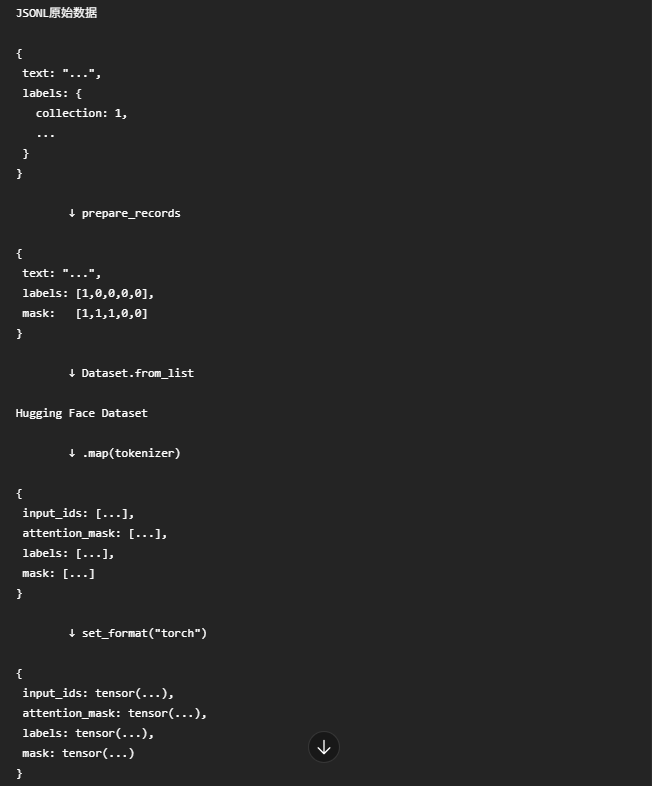

#### Traing

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn sentencepiece

In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)

from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score,
)

In [ ]:
# =========================================================
# Config
# =========================================================

BASE_DIR = Path(
    "/content/drive/MyDrive/TP13_Project"
)

HARD_PATH = (
    BASE_DIR
    / "augmentation"
    / "retention_hard_examples.jsonl"
)

AUGMENTATION_PATH = (
    BASE_DIR
    / "augmentation"
    / "retention_deepseek_600.jsonl"
)

TRAIN_PATH = (
    BASE_DIR
    / "stage1_train_segments_masked.jsonl"
)

VAL_PATH = (
    BASE_DIR
    / "stage1_validation_segments_masked.jsonl"
)

TEST_PATH = (
    BASE_DIR
    / "stage1_test_segments_masked.jsonl"
)

OUTPUT_DIR = (
    BASE_DIR
    / "models"
    / "deberta_v3_base_stage1_retention_aug"
)


MODEL_NAME = "microsoft/deberta-v3-base"


CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control",
]


NUM_LABELS = len(CATEGORIES)


MAX_LENGTH = 384


SEED = 42

In [ ]:
# =========================================================
# Fix random seed
# =========================================================

def set_seed(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

In [ ]:
print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

CUDA available: True
GPU: Tesla T4


In [ ]:
# =========================================================
# Load Jsonl
# =========================================================

def load_jsonl(path):

    records = []

    with open(
        path,
        "r",
        encoding="utf-8"
    ) as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            records.append(
                json.loads(line)
            )

    return records


train_records = load_jsonl(
    TRAIN_PATH
)

val_records = load_jsonl(
    VAL_PATH
)

test_records = load_jsonl(
    TEST_PATH
)


print(
    "Train:",
    len(train_records)
)

print(
    "Validation:",
    len(val_records)
)

print(
    "Test:",
    len(test_records)
)

Train: 13889
Validation: 1432
Test: 6107


add synthetic data


In [ ]:
synthetic_records = load_jsonl(
    AUGMENTATION_PATH
)

print(
    "Synthetic:",
    len(synthetic_records)
)

Synthetic: 600


add hard augmentation

In [ ]:
hard_records = load_jsonl(
    HARD_PATH
)

print(
    "Hard:",
    len(hard_records)
)

Hard: 160


In [ ]:
CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control",
]

for record in synthetic_records:

    record["label_mask"] = {
        category: 1 if record["labels"][category] == 1 else 0
        for category in CATEGORIES
    }

In [ ]:
combined_train_records = (
    train_records
    + synthetic_records
    + hard_records
)

check format

In [ ]:
print(
    json.dumps(
        train_records[0],
        indent=2,
        ensure_ascii=False
    )
)

{
  "id": "APP-350:en:328:seg:0",
  "policy_id": "APP-350:en:328",
  "segment_id": "0",
  "dataset": "APP-350",
  "language": "en",
  "text": "TouchPal Privacy Policy This privacy policy is provided by Shanghai ChuLe (TouchPal) Information Technology Co., Ltd. (\"TouchPal\") and applies to TouchPal Keyboard, including our mobile apps and other various cloud-based services, and the products and services offered in connection with the TouchPal Keyboard. It may be helpful for you to understand what kind of data we collect and how we use it. To provide you with a better keyboard experience, we collect data anonymously on the way you interact with TouchPal Keyboards and data on the performance of TouchPal Keyboards. We take your privacy and data security seriously. We put forth a lot of effort to keep the data that we collect as safe as possible and use it in a proper way.",
  "labels": {
    "data_collection": 0,
    "purpose_of_use": 0,
    "data_sharing": 0,
    "data_retention": 0,
    

In [ ]:
# =========================================================
# Transfer into into label list
# =========================================================

"""
labels = [1,0,0,0,0]

label_mask = [1,0,1,0,0]
"""

def prepare_records(records):

    prepared = []

    for record in records:

        labels = [
            float(
                record["labels"][category]
            )
            for category in CATEGORIES
        ]

        label_mask = [
            float(
                record["label_mask"][category]
            )
            for category in CATEGORIES
        ]

        prepared.append({
            "text":
                record["text"],

            "labels":
                labels,

            "label_mask":
                label_mask,
        })

    return prepared


train_prepared = prepare_records(
    combined_train_records
)

val_prepared = prepare_records(
    val_records
)

test_prepared = prepare_records(
    test_records
)

In [ ]:
# =========================================================
# Create Hugging Face Dataset
# =========================================================

train_dataset = Dataset.from_list(
    train_prepared
)

val_dataset = Dataset.from_list(
    val_prepared
)

test_dataset = Dataset.from_list(
    test_prepared
)

In [ ]:
print(train_dataset)
print(val_dataset)
print(test_dataset)

Dataset({
    features: ['text', 'labels', 'label_mask'],
    num_rows: 14649
})
Dataset({
    features: ['text', 'labels', 'label_mask'],
    num_rows: 1432
})
Dataset({
    features: ['text', 'labels', 'label_mask'],
    num_rows: 6107
})


In [ ]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

In [ ]:
def tokenize_function(batch):

    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=MAX_LENGTH,
    )

In [ ]:
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True,
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True,
)

Map:   0%|          | 0/14649 [00:00<?, ? examples/s]

Map:   0%|          | 0/1432 [00:00<?, ? examples/s]

Map:   0%|          | 0/6107 [00:00<?, ? examples/s]

In [ ]:
# =========================================================
# set dataset foromat
# =========================================================

columns = [
    "input_ids",
    "attention_mask",
    "labels",
    "label_mask",
]


train_dataset.set_format(
    type="torch",
    columns=columns,
)

val_dataset.set_format(
    type="torch",
    columns=columns,
)

test_dataset.set_format(
    type="torch",
    columns=columns,
)

In [ ]:
# =========================================================
# Load DeBERTa-v3-base
# =========================================================

model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        MODEL_NAME,

        num_labels=NUM_LABELS,

        problem_type=
            "multi_label_classification",

        id2label={
            i: category
            for i, category
            in enumerate(CATEGORIES)
        },

        label2id={
            category: i
            for i, category
            in enumerate(CATEGORIES)
        },

        torch_dtype=torch.float32
    )
)


model = model.float()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
pooler.dense.weight                     | MISSING    | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier

In [ ]:
import torch.nn as nn

In [ ]:
# =========================================================
# Trainer
# =========================================================

class MaskedMultiLabelTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):

        labels = inputs.pop(
            "labels"
        )

        label_mask = inputs.pop(
            "label_mask"
        )

        outputs = model(
            **inputs
        )

        logits = outputs.logits


        loss_function = (
            nn.BCEWithLogitsLoss(
                reduction="none"
            )
        )


        raw_loss = loss_function(
            logits,
            labels
        )


        masked_loss = (
            raw_loss
            * label_mask
        )


        denominator = (
            label_mask.sum()
            .clamp(min=1.0)
        )


        loss = (
            masked_loss.sum()
            / denominator
        )


        if return_outputs:

            return (
                loss,
                outputs
            )

        return loss

validation metrics

In [ ]:
threshold = 0.5

In [ ]:
DEFAULT_THRESHOLD = 0.5

In [ ]:
def sigmoid(x):

    return 1 / (
        1 + np.exp(-x)
    )

In [ ]:
def compute_metrics(eval_pred):

    logits, labels = eval_pred

    probabilities = sigmoid(
        logits
    )

    predictions = (
        probabilities
        >= DEFAULT_THRESHOLD
    ).astype(int)


    labels = np.asarray(
        labels
    ).astype(int)


    # -------------------------------------------------
    # Macro metrics
    # -------------------------------------------------

    precision_macro, \
    recall_macro, \
    f1_macro, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        )
    )


    # -------------------------------------------------
    # Micro metrics
    # -------------------------------------------------

    precision_micro, \
    recall_micro, \
    f1_micro, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="micro",
            zero_division=0,
        )
    )


    return {
        "precision_macro":
            precision_macro,

        "recall_macro":
            recall_macro,

        "f1_macro":
            f1_macro,

        "precision_micro":
            precision_micro,

        "recall_micro":
            recall_micro,

        "f1_micro":
            f1_micro,
    }

In [ ]:
training_args = TrainingArguments(

    output_dir=str(
        OUTPUT_DIR
    ),

    # -----------------------
    # epochs
    # -----------------------
    num_train_epochs=5,


    # -----------------------
    # batch size
    # -----------------------
    per_device_train_batch_size=8,

    per_device_eval_batch_size=16,


    # -----------------------
    # optimizer
    # -----------------------
    learning_rate=2e-5,

    weight_decay=0.01,


    # -----------------------
    # warmup
    # -----------------------
    warmup_steps=100,


    # -----------------------
    # evaluation
    # -----------------------
    eval_strategy="epoch",

    save_strategy="epoch",


    # -----------------------
    # best model
    # -----------------------
    load_best_model_at_end=True,

    metric_for_best_model="eval_loss",

    greater_is_better=False,


    # -----------------------
    # checkpoints
    # -----------------------
    save_total_limit=2,


    # -----------------------
    # logging
    # -----------------------
    logging_strategy="steps",

    logging_steps=100,


    # -----------------------
    # GPU
    # -----------------------
    fp16=False,
    bf16=False,


    # -----------------------
    # reproducibility
    # -----------------------
    seed=SEED,


    # -----------------------
    # other
    # -----------------------
    report_to="none",

    # -----------------------
    # keep label_mask
    # -----------------------
    remove_unused_columns=False,
)

Start trainning

In [ ]:
trainer = MaskedMultiLabelTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ],
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.312747,0.296801
2,0.212858,0.297818
3,0.197300,0.302737


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5496, training_loss=0.2640778119560586, metrics={'train_runtime': 4566.4624, 'train_samples_per_second': 16.04, 'train_steps_per_second': 2.006, 'total_flos': 8672595281121024.0, 'train_loss': 0.2640778119560586, 'epoch': 3.0})

Save best model

In [ ]:
BEST_MODEL_DIR = (
    BASE_DIR
    / "models"
    / "deberta_v3_aug_stage1_best"
)

trainer.save_model(
    str(BEST_MODEL_DIR)
)

tokenizer.save_pretrained(
    str(BEST_MODEL_DIR)
)

print(
    "Best model saved to:"
)

print(
    BEST_MODEL_DIR
)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved to:
/content/drive/MyDrive/TP13_Project/models/deberta_v3_aug_stage1_best


#### Validation

Masked evaluation

In [ ]:
val_prediction = trainer.predict(
    val_dataset
)

val_logits = (
    val_prediction.predictions
)

val_probabilities = sigmoid(
    val_logits
)

In [ ]:
val_labels = np.array([
    item["labels"]
    for item in val_prepared
])

val_masks = np.array([
    item["label_mask"]
    for item in val_prepared
])

In [ ]:
def evaluate_masked(
    probabilities,
    labels,
    masks,
    thresholds=None,
):

    if thresholds is None:

        thresholds = np.array(
            [0.5] * NUM_LABELS
        )


    predictions = (
        probabilities
        >= thresholds
    ).astype(int)


    results = {}


    all_true = []
    all_pred = []


    per_class_f1 = []


    for i, category in enumerate(
        CATEGORIES
    ):

        valid = (
            masks[:, i]
            == 1
        )

        y_true = (
            labels[valid, i]
        )

        y_pred = (
            predictions[valid, i]
        )


        precision, recall, f1, _ = (
            precision_recall_fscore_support(
                y_true,
                y_pred,
                average="binary",
                zero_division=0,
            )
        )


        results[category] = {
            "precision":
                float(precision),

            "recall":
                float(recall),

            "f1":
                float(f1),

            "support_positive":
                int(y_true.sum()),

            "evaluated_samples":
                int(len(y_true)),
        }


        per_class_f1.append(
            f1
        )


        all_true.extend(
            y_true.tolist()
        )

        all_pred.extend(
            y_pred.tolist()
        )


    results[
        "macro_f1"
    ] = float(
        np.mean(
            per_class_f1
        )
    )


    precision_micro, \
    recall_micro, \
    f1_micro, _ = (
        precision_recall_fscore_support(
            all_true,
            all_pred,
            average="binary",
            zero_division=0,
        )
    )


    results[
        "micro_precision"
    ] = float(
        precision_micro
    )

    results[
        "micro_recall"
    ] = float(
        recall_micro
    )

    results[
        "micro_f1"
    ] = float(
        f1_micro
    )


    return results

In [ ]:
val_results = evaluate_masked(

    probabilities=
        val_probabilities,

    labels=
        val_labels,

    masks=
        val_masks,
)


print(
    json.dumps(
        val_results,
        indent=2
    )
)

{
  "data_collection": {
    "precision": 0.0,
    "recall": 0.0,
    "f1": 0.0,
    "support_positive": 438,
    "evaluated_samples": 1432
  },
  "purpose_of_use": {
    "precision": 0.6337579617834395,
    "recall": 1.0,
    "f1": 0.7758284600389863,
    "support_positive": 398,
    "evaluated_samples": 628
  },
  "data_sharing": {
    "precision": 0.125,
    "recall": 0.004310344827586207,
    "f1": 0.008333333333333333,
    "support_positive": 232,
    "evaluated_samples": 1432
  },
  "data_retention": {
    "precision": 0.03980891719745223,
    "recall": 1.0,
    "f1": 0.07656967840735068,
    "support_positive": 25,
    "evaluated_samples": 628
  },
  "user_control": {
    "precision": 0.09090909090909091,
    "recall": 0.02631578947368421,
    "f1": 0.04081632653061224,
    "support_positive": 114,
    "evaluated_samples": 628
  },
  "macro_f1": 0.18030955966205653,
  "micro_precision": 0.3292212798766384,
  "micro_recall": 0.35376967688483846,
  "micro_f1": 0.34105431309904155


In [ ]:
"""
find  best threshold for each class
"""

def find_best_thresholds(
    probabilities,
    labels,
    masks,
):

    thresholds = {}


    search_values = np.arange(
        0.10,
        0.91,
        0.05
    )


    for i, category in enumerate(
        CATEGORIES
    ):

        valid = (
            masks[:, i]
            == 1
        )


        y_true = (
            labels[
                valid,
                i
            ]
        )


        y_prob = (
            probabilities[
                valid,
                i
            ]
        )


        best_threshold = 0.5
        best_f1 = -1


        for threshold in search_values:

            y_pred = (
                y_prob
                >= threshold
            ).astype(int)


            f1 = f1_score(
                y_true,
                y_pred,
                zero_division=0
            )


            if f1 > best_f1:

                best_f1 = f1
                best_threshold = (
                    threshold
                )


        thresholds[
            category
        ] = {
            "threshold":
                float(
                    round(
                        best_threshold,
                        2
                    )
                ),

            "validation_f1":
                float(
                    best_f1
                )
        }


    return thresholds

In [ ]:
best_thresholds = (
    find_best_thresholds(
        val_probabilities,
        val_labels,
        val_masks,
    )
)


print(
    json.dumps(
        best_thresholds,
        indent=2
    )
)

{
  "data_collection": {
    "threshold": 0.1,
    "validation_f1": 0.46844919786096256
  },
  "purpose_of_use": {
    "threshold": 0.1,
    "validation_f1": 0.7758284600389863
  },
  "data_sharing": {
    "threshold": 0.1,
    "validation_f1": 0.27884615384615385
  },
  "data_retention": {
    "threshold": 0.1,
    "validation_f1": 0.07656967840735068
  },
  "user_control": {
    "threshold": 0.1,
    "validation_f1": 0.30727762803234504
  }
}


use best threshold to evaluate again

In [ ]:
threshold_array = np.array([
    best_thresholds[
        category
    ]["threshold"]

    for category
    in CATEGORIES
])

In [ ]:
val_tuned_results = (
    evaluate_masked(

        probabilities=
            val_probabilities,

        labels=
            val_labels,

        masks=
            val_masks,

        thresholds=
            threshold_array,
    )
)


print(
    json.dumps(
        val_tuned_results,
        indent=2
    )
)

{
  "data_collection": {
    "precision": 0.3058659217877095,
    "recall": 1.0,
    "f1": 0.46844919786096256,
    "support_positive": 438,
    "evaluated_samples": 1432
  },
  "purpose_of_use": {
    "precision": 0.6337579617834395,
    "recall": 1.0,
    "f1": 0.7758284600389863,
    "support_positive": 398,
    "evaluated_samples": 628
  },
  "data_sharing": {
    "precision": 0.16201117318435754,
    "recall": 1.0,
    "f1": 0.27884615384615385,
    "support_positive": 232,
    "evaluated_samples": 1432
  },
  "data_retention": {
    "precision": 0.03980891719745223,
    "recall": 1.0,
    "f1": 0.07656967840735068,
    "support_positive": 25,
    "evaluated_samples": 628
  },
  "user_control": {
    "precision": 0.18152866242038215,
    "recall": 1.0,
    "f1": 0.30727762803234504,
    "support_positive": 114,
    "evaluated_samples": 628
  },
  "macro_f1": 0.3813942236371597,
  "micro_precision": 0.254212299915754,
  "micro_recall": 1.0,
  "micro_f1": 0.40537363560033585
}


#### Test

In [ ]:
test_prediction = (
    trainer.predict(
        test_dataset
    )
)


test_logits = (
    test_prediction.predictions
)


test_probabilities = sigmoid(
    test_logits
)

In [ ]:
test_labels = np.array([
    item["labels"]
    for item in test_prepared
])


test_masks = np.array([
    item["label_mask"]
    for item in test_prepared
])

In [ ]:
test_results = evaluate_masked(

    probabilities=
        test_probabilities,

    labels=
        test_labels,

    masks=
        test_masks,

    thresholds=
        threshold_array,
)


print(
    json.dumps(
        test_results,
        indent=2
    )
)

{
  "data_collection": {
    "precision": 0.2312100867856558,
    "recall": 1.0,
    "f1": 0.3755818592897992,
    "support_positive": 1412,
    "evaluated_samples": 6107
  },
  "purpose_of_use": {
    "precision": 0.4397270659590599,
    "recall": 1.0,
    "f1": 0.6108478146392838,
    "support_positive": 580,
    "evaluated_samples": 1319
  },
  "data_sharing": {
    "precision": 0.10496151956770919,
    "recall": 1.0,
    "f1": 0.1899822169531713,
    "support_positive": 641,
    "evaluated_samples": 6107
  },
  "data_retention": {
    "precision": 0.04639175257731959,
    "recall": 1.0,
    "f1": 0.08866995073891626,
    "support_positive": 27,
    "evaluated_samples": 582
  },
  "user_control": {
    "precision": 0.1728582259287339,
    "recall": 1.0,
    "f1": 0.29476405946994183,
    "support_positive": 228,
    "evaluated_samples": 1319
  },
  "macro_f1": 0.31196918021822245,
  "micro_precision": 0.18711934689646237,
  "micro_recall": 1.0,
  "micro_f1": 0.3152494269184587
}


save threshold (needed for deployment)

In [ ]:
BEST_MODEL_DIR = (
    BASE_DIR
    / "models"
    / "deberta_v3_aug_stage1_best"
)

In [ ]:
THRESHOLD_PATH = (
    BEST_MODEL_DIR
    / "thresholds.json"
)


with open(
    THRESHOLD_PATH,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        best_thresholds,
        f,
        indent=2
    )


print(
    "Thresholds saved:"
)

print(
    THRESHOLD_PATH
)

Thresholds saved:
/content/drive/MyDrive/TP13_Project/models/deberta_v3_aug_stage1_best/thresholds.json


#### sample test

In [ ]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model.to(device)

model.eval()

DebertaV2ForSequenceClassification(
  (deberta): DebertaV2Model(
    (embeddings): DebertaV2Embeddings(
      (word_embeddings): Embedding(128100, 768, padding_idx=0)
      (LayerNorm): LayerNorm((768,), eps=1e-07, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): DebertaV2Encoder(
      (layer): ModuleList(
        (0-11): 12 x DebertaV2Layer(
          (attention): DebertaV2Attention(
            (self): DisentangledSelfAttention(
              (query_proj): Linear(in_features=768, out_features=768, bias=True)
              (key_proj): Linear(in_features=768, out_features=768, bias=True)
              (value_proj): Linear(in_features=768, out_features=768, bias=True)
              (pos_dropout): Dropout(p=0.1, inplace=False)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): DebertaV2SelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): Layer

In [ ]:
def predict_segment(
    text,
    model,
    tokenizer,
    thresholds,
):

    inputs = tokenizer(

        text,

        return_tensors="pt",

        truncation=True,

        padding=True,

        max_length=MAX_LENGTH,
    )


    inputs = {
        key: value.to(device)
        for key, value
        in inputs.items()
    }


    with torch.no_grad():

        outputs = model(
            **inputs
        )


    logits = (
        outputs.logits
        .cpu()
        .numpy()[0]
    )


    probabilities = sigmoid(
        logits
    )


    result = {}


    for i, category in enumerate(
        CATEGORIES
    ):

        threshold = thresholds[
            category
        ]["threshold"]


        result[category] = {

            "probability":
                float(
                    probabilities[i]
                ),

            "threshold":
                threshold,

            "predicted_label":
                int(
                    probabilities[i]
                    >= threshold
                )
        }


    return result

In [ ]:
sample_text = """
We retain transaction records for seven years
to comply with financial and legal obligations.
You may request deletion of other account information
through your account settings.
"""


result = predict_segment(

    sample_text,

    model,

    tokenizer,

    best_thresholds,
)


print(
    json.dumps(
        result,
        indent=2
    )
)

{
  "data_collection": {
    "probability": 0.46807464957237244,
    "threshold": 0.1,
    "predicted_label": 1
  },
  "purpose_of_use": {
    "probability": 0.5088538527488708,
    "threshold": 0.1,
    "predicted_label": 1
  },
  "data_sharing": {
    "probability": 0.4980575442314148,
    "threshold": 0.1,
    "predicted_label": 1
  },
  "data_retention": {
    "probability": 0.5492783188819885,
    "threshold": 0.1,
    "predicted_label": 1
  },
  "user_control": {
    "probability": 0.497835636138916,
    "threshold": 0.1,
    "predicted_label": 1
  }
}


#### segment predictions

In [ ]:
import torch

CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control"
]


def predict_segments(
    segments,
    model,
    tokenizer,
    max_length=384
):
    """
    Run Stage 1 DeBERTa inference on all segments.

    Input:
        segments = [
            {
                "segment_id": "...",
                "text": "..."
            },
            ...
        ]

    Output:
        segment_predictions = [
            {
                "segment_id": "...",
                "text": "...",
                "probabilities": {
                    "data_collection": ...,
                    ...
                }
            },
            ...
        ]
    """

    model.eval()

    device = next(model.parameters()).device

    segment_predictions = []

    for segment in segments:

        text = segment["text"]

        # ---------------------------------------------
        # Tokenize
        # ---------------------------------------------
        inputs = tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            padding=True,
            max_length=max_length
        )

        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # ---------------------------------------------
        # DeBERTa inference
        # ---------------------------------------------
        with torch.no_grad():

            outputs = model(**inputs)

            logits = outputs.logits

            probabilities = torch.sigmoid(
                logits
            )[0].cpu().numpy()

        # ---------------------------------------------
        # Convert to dictionary
        # ---------------------------------------------
        probability_dict = {
            category: float(probabilities[i])
            for i, category in enumerate(CATEGORIES)
        }

        segment_predictions.append({
            "segment_id": segment["segment_id"],
            "text": text,
            "probabilities": probability_dict
        })

    return segment_predictions

In [ ]:
policy = """We collect personal information when you create an account or use our services. This may include your name, email address, phone number, location, device information, IP address,
and information about how you use our website. We use this information to provide and improve our services, personalise your experience, communicate with you, prevent fraud, and analyse website usage. We may also use your email address to send you promotional messages and special offers. You can unsubscribe
from marketing emails at any time.
We may share your personal information with trusted third-party service providers, including
cloud hosting providers, analytics services, payment providers, and advertising partners.
These third parties may process your information on our behalf. We may also disclose
information if required by law or to protect our legal rights.
Our website uses cookies and similar technologies to remember your preferences,
understand how you use the website, and provide personalised advertising. Some cookies
are necessary for the website to work, while others are used for analytics and marketing.
We keep your personal information for as long as necessary to provide our services and
meet legal requirements. Some information may be stored for up to seven years after you
stop using our services.
You may request access to, correction of, or deletion of your personal information. You may
also withdraw your consent for certain uses of your data. However, withdrawing consent may
affect your ability to use some features of the service.
By clicking “I Agree” or continuing to use our service, you acknowledge that you have read
this Privacy Notice and consent to the collection, use, storage, and sharing of your personal
information as described above."""

In [ ]:
segments = segment_policy(policy)

In [ ]:
segments = segment_policy(policy)

for segment in segments:

    print("=" * 100)

    print(
        "Segment:",
        segment["segment_id"]
    )



    print()

    print(
        segment["text"]
    )

Segment: 0

We collect personal information when you create an account or use our services. This may include your name, email address, phone number, location, device information, IP address, and information about how you use our website.
Segment: 1

We use this information to provide and improve our services, personalise your experience, communicate with you, prevent fraud, and analyse website usage. We may also use your email address to send you promotional messages and special offers.
Segment: 2

You can unsubscribe from marketing emails at any time. We may share your personal information with trusted third-party service providers, including cloud hosting providers, analytics services, payment providers, and advertising partners.
Segment: 3

These third parties may process your information on our behalf. We may also disclose information if required by law or to protect our legal rights.
Segment: 4

Our website uses cookies and similar technologies to remember your preferences, unders

In [ ]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

BEST_MODEL_DIR = (
    "/content/drive/MyDrive/TP13_Project/"
    "models/deberta_v3_aug_stage1_best"
)

# Stage 1 tokenizer
stage1_tokenizer = AutoTokenizer.from_pretrained(
    BEST_MODEL_DIR
)

# Stage 1 best model
stage1_model = AutoModelForSequenceClassification.from_pretrained(
    BEST_MODEL_DIR
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


stage1_model.to(device)
stage1_model.eval()

print("Stage 1 model loaded successfully")
print("Device:", device)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Stage 1 model loaded successfully
Device: cpu


In [ ]:
segment_predictions = predict_segments(
    segments=segments,
    model=stage1_model,
    tokenizer=stage1_tokenizer
)

## Intermediate representation

In [ ]:
import json
from typing import List, Dict, Any

In [ ]:
# ============================================================
# 1. Categories
# ============================================================

CATEGORIES = [
    "data_collection",
    "purpose_of_use",
    "data_sharing",
    "data_retention",
    "user_control",
]

Replace these with validation-tuned thresholds！！！！！！！


In [ ]:
# ============================================================
# 2. Thresholds
# ============================================================

DEFAULT_THRESHOLDS = {
    "data_collection": 0.10,
    "purpose_of_use": 0.10,
    "data_sharing": 0.10,
    "data_retention": 0.10,
    "user_control": 0.10,
}

In [ ]:
# ============================================================
# 3. Build Intermediate Representation
# ============================================================

def build_intermediate_representation(
    policy_id: str,
    segment_predictions: List[Dict[str, Any]],
    thresholds: Dict[str, float] = None,
) -> Dict[str, Any]:
    """
    Convert Stage 1 segment-level predictions into
    category-wise evidence groups.

    Expected segment_predictions format:

    [
        {
            "segment_id": "1",
            "text": "...",
            "probabilities": {
                "data_collection": 0.91,
                "purpose_of_use": 0.23,
                "data_sharing": 0.07,
                "data_retention": 0.05,
                "user_control": 0.03
            }
        },
        ...
    ]
    """

    if thresholds is None:
        thresholds = DEFAULT_THRESHOLDS

    # --------------------------------------------------------
    # Create empty IR
    # --------------------------------------------------------

    ir = {
        "policy_id": policy_id,
        "categories": {
            category: {
                "evidence": []
            }
            for category in CATEGORIES
        }
    }

    # --------------------------------------------------------
    # Process every segment
    # --------------------------------------------------------

    for segment in segment_predictions:

        segment_id = segment.get("segment_id")
        text = (segment.get("text") or "").strip()
        probabilities = segment.get("probabilities", {})

        if not text:
            continue

        # A single segment may belong to multiple categories.
        for category in CATEGORIES:

            probability = float(
                probabilities.get(category, 0.0)
            )

            threshold = float(
                thresholds[category]
            )

            if probability >= threshold:

                ir["categories"][category]["evidence"].append({
                    "segment_id": segment_id,
                    "text": text,
                    "confidence": probability,
                })

    return ir

In [ ]:
ir = build_intermediate_representation(
    policy_id="policy_001",
    segment_predictions=segment_predictions,
    thresholds=DEFAULT_THRESHOLDS
)

In [ ]:
print(
    json.dumps(
        ir,
        indent=2,
        ensure_ascii=False
    )
)

{
  "policy_id": "policy_001",
  "categories": {
    "data_collection": {
      "evidence": [
        {
          "segment_id": 0,
          "text": "We collect personal information when you create an account or use our services. This may include your name, email address, phone number, location, device information, IP address, and information about how you use our website.",
          "confidence": 0.9809159636497498
        },
        {
          "segment_id": 1,
          "text": "We use this information to provide and improve our services, personalise your experience, communicate with you, prevent fraud, and analyse website usage. We may also use your email address to send you promotional messages and special offers.",
          "confidence": 0.9752031564712524
        },
        {
          "segment_id": 4,
          "text": "Our website uses cookies and similar technologies to remember your preferences, understand how you use the website, and provide personalised advertising. Some

In [ ]:
def sort_ir_evidence_by_segment_id(ir):

    for category in CATEGORIES:

        evidence = (
            ir["categories"]
            [category]
            ["evidence"]
        )

        evidence.sort(
            key=lambda x: int(x["segment_id"])
        )

    return ir

In [ ]:
def add_ir_metadata(ir):

    for category in CATEGORIES:

        evidence = (
            ir["categories"]
            [category]
            ["evidence"]
        )

        confidences = [
            item["confidence"]
            for item in evidence
        ]

        ir["categories"][category]["metadata"] = {
            "evidence_count": len(evidence),

            "max_confidence": (
                max(confidences)
                if confidences
                else None
            ),

            "mean_confidence": (
                sum(confidences) / len(confidences)
                if confidences
                else None
            )
        }

    return ir

In [ ]:
ir = build_intermediate_representation(
    policy_id="policy_001",
    segment_predictions=segment_predictions,
    thresholds=DEFAULT_THRESHOLDS
)

ir = sort_ir_evidence_by_segment_id(ir)

ir = add_ir_metadata(ir)

In [ ]:
print(
    json.dumps(
        ir,
        indent=2,
        ensure_ascii=False
    )
)

{
  "policy_id": "policy_001",
  "categories": {
    "data_collection": {
      "evidence": [
        {
          "segment_id": 0,
          "text": "We collect personal information when you create an account or use our services. This may include your name, email address, phone number, location, device information, IP address, and information about how you use our website.",
          "confidence": 0.9809159636497498
        },
        {
          "segment_id": 1,
          "text": "We use this information to provide and improve our services, personalise your experience, communicate with you, prevent fraud, and analyse website usage. We may also use your email address to send you promotional messages and special offers.",
          "confidence": 0.9752031564712524
        },
        {
          "segment_id": 4,
          "text": "Our website uses cookies and similar technologies to remember your preferences, understand how you use the website, and provide personalised advertising. Some

#### 部署时候要添加UID


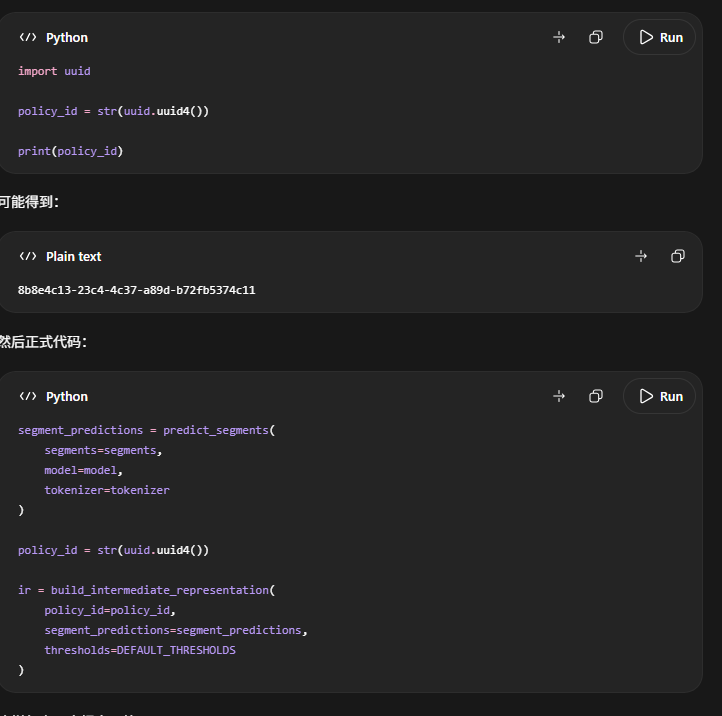
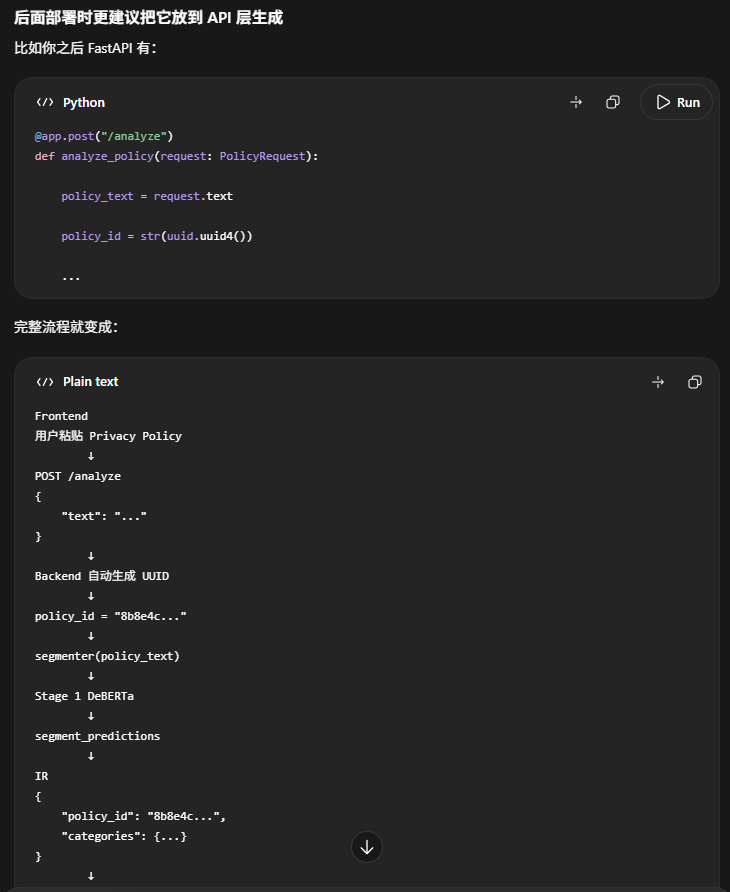

In [ ]:
import uuid

policy_id = str(uuid.uuid4())

print(policy_id)

In [ ]:
segment_predictions = predict_segments(
    segments=segments,
    model=model,
    tokenizer=tokenizer
)

policy_id = str(uuid.uuid4())

ir = build_intermediate_representation(
    policy_id=policy_id,
    segment_predictions=segment_predictions,
    thresholds=DEFAULT_THRESHOLDS
)

In [ ]:
@app.post("/analyze")
def analyze_policy(request: PolicyRequest):

    policy_text = request.text

    policy_id = str(uuid.uuid4())

    ...

## Prompt engineering -- Stage 2 (summary)

#### prompt engineering

In [ ]:
CATEGORY_FIELDS = {
    "data_collection": [
        "what_data_is_collected",
        "how_it_is_collected",
        "when_collection_happens",
        "required_or_optional",
        "what_is_not_confirmed",
        "why_this_matters",
    ],

    "purpose_of_use": [
        "why_data_is_used",
        "data_and_purpose",
        "unspecified_purposes",
        "additional_uses",
        "why_this_matters",
    ],

    "data_sharing": [
        "who_data_may_be_shared_with",
        "why_sharing_may_happen",
        "named_organisations",
        "what_data_is_shared",
        "user_control",
        "why_this_matters",
    ],

    "data_retention": [
        "what_is_retained",
        "how_long_data_is_kept",
        "why_data_is_retained",
        "deletion_condition",
        "why_this_matters",
    ],

    "user_control": [
        "what_you_can_control",
        "how_to_use_these_controls",
        "access_and_correction",
        "deletion",
        "consent_or_opt_out",
        "limitations",
        "why_this_matters",
    ],
}

standardise format

In [ ]:
def format_evidence(evidence):
    """
    evidence:
    [
        {
            "segment_id": 3,
            "text": "..."
        },
        ...
    ]
    """

    blocks = []

    for i, item in enumerate(evidence, start=1):
        blocks.append(
            f"[Evidence {i} | segment_id={item['segment_id']}]\n"
            f"{item['text']}"
        )

    return "\n\n".join(blocks)

prompt builder

In [ ]:
def build_stage2_prompt(category, evidence):

    fields = CATEGORY_FIELDS[category]

    evidence_text = format_evidence(evidence)

    detail_template = {
        field: (
            f"<Write the answer for {field} using only the evidence, "
            f"or return null if not supported>"
        )
        for field in fields
    }

    output_template = {
        "summary": (
            "<Write a concise 1-2 sentence user-friendly summary "
            "of the evidence. If evidence exists, do NOT return null.>"
        ),
        "detailed_explanation": detail_template
    }

    prompt = f"""
You are analysing a privacy policy for end users.

Category:
{category}

Use ONLY the evidence below.

STRICT RULES:

1. The summary is REQUIRED whenever relevant evidence is provided.
2. Write the summary in 1-2 concise sentences using simple English.
3. Do NOT return null for summary if the evidence contains information
   relevant to the category.
4. For detailed fields, return null ONLY when that specific information
   is not supported by the evidence.
5. Do not invent missing information.
6. Preserve conditions, exceptions, uncertainty, and negation.
7. "why_this_matters" may explain the practical significance for the user,
   but must not introduce new claims about the organisation.
8. Return valid JSON only.
9. Do not include Markdown or commentary outside the JSON.

IMPORTANT:
When a field is unsupported, output the JSON value null.
Do NOT write phrases such as:
- "Not specified"
- "Not mentioned"
- "No information available"
- "Unknown"

Evidence:

{evidence_text}

Return exactly this JSON structure:

{json.dumps(output_template, indent=2)}
"""

    return prompt.strip()

load LLM model

In [ ]:
!pip install -q transformers accelerate sentencepiece

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

STAGE2_MODEL_NAME  = "Qwen/Qwen2.5-3B-Instruct"

stage2_tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    trust_remote_code=True
)

stage2_model  = AutoModelForCausalLM.from_pretrained(
    STAGE2_MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True
)

stage2_model.eval()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151936, 2048)
    (layers): ModuleList(
      (0-35): 36 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=True)
          (k_proj): Linear(in_features=2048, out_features=256, bias=True)
          (v_proj): Linear(in_features=2048, out_features=256, bias=True)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=2048, out_features=11008, bias=False)
          (up_proj): Linear(in_features=2048, out_features=11008, bias=False)
          (down_proj): Linear(in_features=11008, out_features=2048, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((2048,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((2048,), eps=1e-06)
    (ro

In [ ]:
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: False


generate summary

In [ ]:
def generate_category_summary(
    category,
    evidence,
    model,
    tokenizer,
    max_new_tokens=700
):

    # if no evidence return none
    if not evidence:

        return {
            "summary": None,
            "detailed_explanation": {
                field: None
                for field in CATEGORY_FIELDS[category]
            }
        }

    prompt = build_stage2_prompt(
        category=category,
        evidence=evidence
    )

    messages = [
        {
            "role": "system",
            "content": (
                "You are a grounded privacy-policy summarisation assistant. "
                "Never add facts that are not supported by the supplied evidence."
            )
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True
    ).to(model.device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated_tokens = outputs[
        0,
        inputs["input_ids"].shape[1]:
    ]

    response = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    ).strip()

    return response

#### final generation

In [ ]:
def generate_all_summaries(ir, model, tokenizer):

    results = {}

    for category in CATEGORY_FIELDS:

        evidence = (
            ir["categories"]
            [category]
            ["evidence"]
        )

        results[category] = (
            generate_category_summary(
                category=category,
                evidence=evidence,
                model=model,
                tokenizer=tokenizer
            )
        )

    return results

#### sample test

In [ ]:
retention_evidence = (
    ir["categories"]
    ["data_retention"]
    ["evidence"]
)

response = generate_category_summary(
    category="data_retention",
    evidence=retention_evidence,
    model=stage2_model,
    tokenizer=stage2_tokenizer
)

print(response)

{
  "summary": "Your personal information is kept until we need it for services or laws require it, up to 7 years after you stop using our services.",
  "detailed_explanation": {
    "what_is_retained": "Personal information",
    "how_long_data_is_kept": "Up to 7 years after stopping service use",
    "why_data_is_retained": "To provide services and meet legal requirements",
    "deletion_condition": null,
    "why_this_matters": "Ensures compliance with laws and provides necessary data for service operations"
  }
}


In [ ]:
summary = generate_all_summaries(ir, model=stage2_model, tokenizer=stage2_tokenizer)

In [ ]:
print(
    json.dumps(
        summary,
        indent=2,
        ensure_ascii=False
    )
)

{
  "data_collection": "{\n  \"summary\": \"When you use our services, we collect various types of information like your name, email, location, and how you use our site to improve your experience and show you ads.\",\n  \"detailed_explanation\": {\n    \"what_data_is_collected\": \"Your name, email address, phone number, location, device information, IP address, and information about how you use our website.\",\n    \"how_it_is_collected\": \"We collect this information when you create an account or use our services.\",\n    \"when_collection_happens\": \"We collect this information when you interact with our services.\",\n    \"required_or_optional\": \"Some data collection is required for service provision, while others are optional for improving services and personalising experiences.\",\n    \"what_is_not_confirmed\": \"Null\",\n    \"why_this_matters\": \"This helps us provide better services and shows you targeted ads.\"\n  }\n}",
  "purpose_of_use": "{\n  \"summary\": \"We colle

## whole workflow

In [ ]:
# =====================================================
# Application startup
# =====================================================

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    AutoModelForCausalLM
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# =====================================================
# Stage 1 — DeBERTa
# =====================================================

STAGE1_MODEL_PATH = "./models/deberta_stage1_best"

stage1_tokenizer = AutoTokenizer.from_pretrained(
    STAGE1_MODEL_PATH
)

stage1_model = AutoModelForSequenceClassification.from_pretrained(
    STAGE1_MODEL_PATH
)

stage1_model.to(device)
stage1_model.eval()


# =====================================================
# Stage 2 — Qwen
# =====================================================

STAGE2_MODEL_PATH = "Qwen/Qwen2.5-3B-Instruct"

stage2_tokenizer = AutoTokenizer.from_pretrained(
    STAGE2_MODEL_PATH
)

stage2_model = AutoModelForCausalLM.from_pretrained(
    STAGE2_MODEL_PATH,
    torch_dtype="auto",
    device_map="auto"
)

stage2_model.eval()

In [ ]:
@app.post("/analyze")
def analyze_policy(request):

    # 1. 用户输入
    policy_text = request.text

    # 2. Segmentation
    segments = segment_policy(
        policy_text
    )

    # 3. Stage 1
    segment_predictions = predict_segments(
        segments=segments,
        model=stage1_model,
        tokenizer=stage1_tokenizer
    )

    # 4. Intermediate Representation
    ir = build_intermediate_representation(
        policy_id=str(uuid.uuid4()),
        segment_predictions=segment_predictions,
        thresholds=STAGE1_THRESHOLDS
    )

    # 5. Stage 2
    result = generate_summaries(
        ir=ir,
        model=stage2_model,
        tokenizer=stage2_tokenizer
    )

    return result